# От U-Net к сегментации через queries

U-Net → фиксированные каналы масок и matching → обновляемые queries → masked attention → несколько масштабов.

Модели, данные, обучение и графики реализованы в этом ноутбуке. Сохранённые результаты можно читать без повторного обучения.

[Запуск](../README.md) · [Пояснения и статьи](../ADDITIONAL_NOTES.md)

## Подготовка

Python 3.12. В новом окружении установите зависимости:

```python
%pip install torch numpy scipy matplotlib
```

По умолчанию: CPU, синтетические фигуры, случайная инициализация. Данные генерируются ниже.
`TRAIN_STEPS` задаёт длительность переобучения на восьми изображениях, `COMPARISON_STEPS` — каждого парного обучения.
Все реализации и параметры находятся в ноутбуке; графики и веса сохраняются в `segmentation_outputs` в рабочей папке kernel.

In [1]:
from pathlib import Path
import json
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.optimize import linear_sum_assignment
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


torch.set_num_threads(2)
seed_everything(42)
DEVICE = torch.device("cpu")
TRAIN_STEPS = 100
COMPARISON_STEPS = 200
ARTIFACTS = Path.cwd() / "segmentation_outputs"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print("PyTorch:", torch.__version__, "device:", DEVICE)

PyTorch: 2.14.1 device: cpu


In [2]:
from matplotlib.patches import FancyBboxPatch

TALK_FIGURES = ARTIFACTS / "talk_figures"
TALK_FIGURES.mkdir(exist_ok=True)


def finish_visual(figure, name):
    figure.savefig(TALK_FIGURES / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(figure)


def diagram_canvas(title, size=(13, 5)):
    figure, axis = plt.subplots(figsize=size)
    axis.set(xlim=(-0.2, 12.45), ylim=(0, 5))
    axis.axis("off")
    axis.set_title(title, fontsize=17, pad=16)
    return figure, axis


def diagram_box(axis, center, text, width=2, height=0.8, color="#e5eff9", fontsize=12):
    x, y = center
    axis.add_patch(FancyBboxPatch((x - width / 2, y - height / 2), width, height,
                                 boxstyle="round,pad=0.04", facecolor=color, edgecolor="#40556b", linewidth=1.2))
    axis.text(x, y, text, ha="center", va="center", fontsize=fontsize)


def diagram_arrow(axis, start, end, color="#40556b", style="-", curve=0):
    axis.annotate("", xy=end, xytext=start,
                  arrowprops={"arrowstyle": "->", "color": color, "lw": 1.6,
                              "linestyle": style, "connectionstyle": f"arc3,rad={curve}"})

### Данные

Круги и прямоугольники с перекрытиями. Target содержит только видимые части экземпляров; у пустого изображения — ноль масок.

In [3]:
class ShapesDataset(Dataset):
    """Deterministic visible instances; labels 0=circle, 1=rectangle."""

    class_names = ("circle", "rectangle")

    def __init__(self, count=32, image_size=(64, 96), seed=42):
        self.count, self.image_size, self.seed = count, tuple(image_size), seed

    def __len__(self):
        return self.count

    def __getitem__(self, index):
        rng = np.random.default_rng(self.seed + index)
        height, width = self.image_size
        yy, xx = np.mgrid[:height, :width]
        image = rng.uniform(0.05, 0.15, (height, width, 3)).astype(np.float32)
        instance_map = np.zeros((height, width), dtype=np.int64)
        labels = []
        objects = 0 if index % 11 == 0 else int(rng.integers(1, 4))
        for instance in range(objects):
            label = int(rng.integers(0, 2))
            cx, cy = rng.uniform(0.15, 0.85) * width, rng.uniform(0.15, 0.85) * height
            rx, ry = rng.uniform(0.08, 0.2) * width, rng.uniform(0.1, 0.25) * height
            if label == 0:
                mask = ((xx - cx) / rx) ** 2 + ((yy - cy) / ry) ** 2 <= 1
            else:
                mask = (abs(xx - cx) < rx) & (abs(yy - cy) < ry)
            color = np.array([0.85, 0.3, 0.2] if label == 0 else [0.2, 0.7, 0.9])
            image[mask] = np.clip(color + rng.uniform(-0.1, 0.1, 3), 0, 1)
            instance_map[mask] = instance + 1
            labels.append(label)
        masks, visible_labels = [], []
        for instance, label in enumerate(labels, 1):
            mask = instance_map == instance
            if mask.any():
                masks.append(torch.from_numpy(mask))
                visible_labels.append(label)
        target = {
            "labels": torch.tensor(visible_labels, dtype=torch.long),
            "masks": torch.stack(masks).float() if masks else torch.zeros(0, height, width),
        }
        return torch.from_numpy(image.transpose(2, 0, 1)).float(), target


def collate_instances(batch):
    images, targets = zip(*batch)
    return torch.stack(images), list(targets)


def targets_to_device(targets, device):
    return [{key: value.to(device) for key, value in target.items()} for target in targets]


def semantic_targets(targets):
    result = []
    for target in targets:
        masks, labels = target["masks"], target["labels"]
        semantic = torch.zeros(masks.shape[-2:], dtype=torch.long, device=masks.device)
        for mask, label in zip(masks, labels):
            semantic[mask > 0.5] = label + 1
        result.append(semantic)
    return torch.stack(result)

In [4]:
def show_batch(images, targets, max_images=4):
    count = min(len(images), max_images)
    fig, axes = plt.subplots(count, 3, figsize=(11, 3 * count), squeeze=False)
    semantic = semantic_targets(targets)
    for row in range(count):
        axes[row, 0].imshow(images[row].detach().cpu().permute(1, 2, 0).clamp(0, 1))
        axes[row, 1].imshow(semantic[row].cpu(), vmin=0, vmax=2, cmap="tab10")
        instances = torch.zeros(targets[row]["masks"].shape[-2:])
        for index, mask in enumerate(targets[row]["masks"]):
            instances[mask.cpu() > 0.5] = index + 1
        axes[row, 2].imshow(instances, vmin=0, vmax=8, cmap="tab10")
        for ax, title in zip(axes[row], ["Image", "Semantic target", "Instance target"]):
            ax.set_title(title)
            ax.axis("off")
    fig.tight_layout()
    return fig

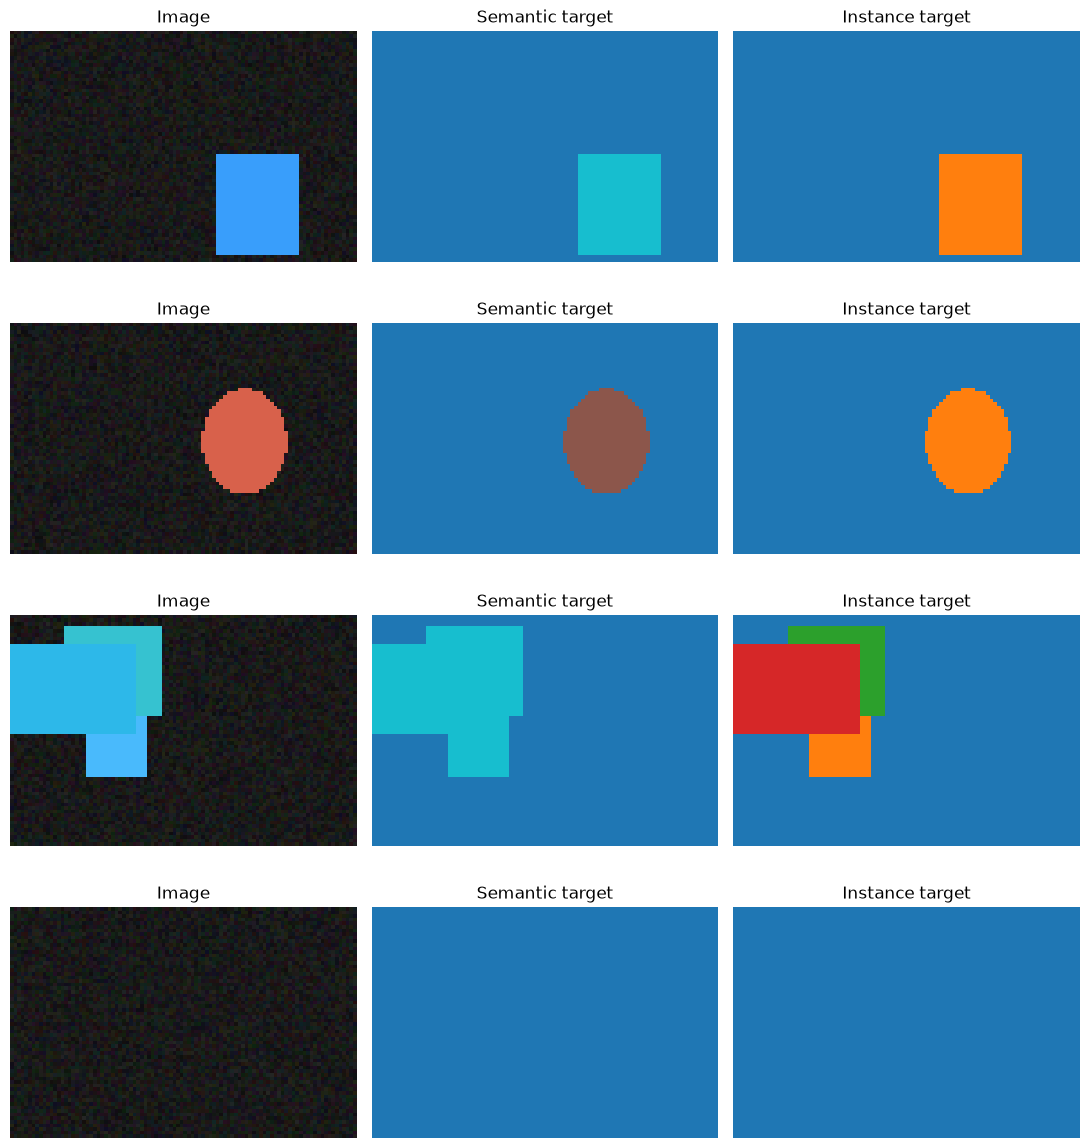

Images: (4, 3, 64, 96)
Instances: [1, 1, 3, 0]


In [5]:
dataset = ShapesDataset(count=16, seed=42)
images, targets = collate_instances([dataset[i] for i in [1, 2, 3, 11]])
images = images.to(DEVICE)
targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
show_batch(images, targets)
plt.show()
print("Images:", tuple(images.shape))
print("Instances:", [len(t["labels"]) for t in targets])

## 1. Последняя свёртка U-Net

Для признаков $F\in\mathbb{R}^{D\times H\times W}$ свёртка $1\times1$ вычисляет

$$s_c(x,y)=w_c^\top F(x,y)+b_c.$$

Веса $w_c$ фиксированы после обучения; признаки $F$ зависят от изображения. Каждый выходной канал соответствует классу.

Один канал класса объединяет его экземпляры. Для отдельных объектов можно выделить отдельные выходные каналы: например, предсказывать 100 масок и класс каждой маски.

### Один класс, несколько экземпляров

Изображение из нашего генератора. Для semantic target маски одного класса объединяются; для instance target сохраняется отдельная маска каждого объекта.

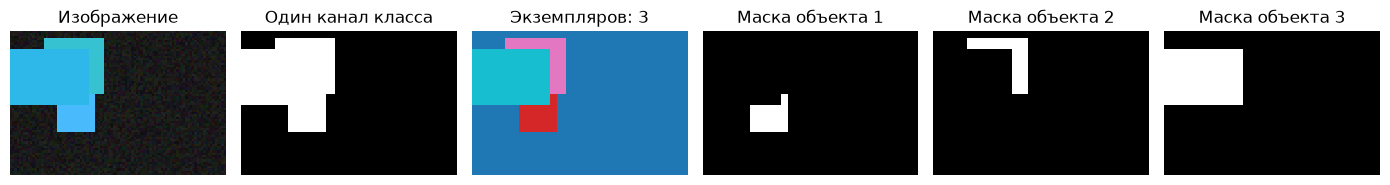

In [6]:
def show_semantic_instances():
    for index in range(len(dataset)):
        image, target = dataset[index]
        if len(target["labels"]) >= 2 and torch.bincount(target["labels"], minlength=2).max() >= 2:
            break
    repeated_class = int(torch.bincount(target["labels"], minlength=2).argmax())
    masks = target["masks"][target["labels"] == repeated_class]
    merged = masks.bool().any(0)
    canvas = torch.zeros_like(merged, dtype=torch.long)
    for obj, mask in enumerate(masks, 1):
        canvas[mask.bool()] = obj
    figure, axes = plt.subplots(1, 3 + len(masks), figsize=(14, 3))
    panels = [(image.permute(1, 2, 0), "Изображение"), (merged, "Один канал класса"),
              (canvas, f"Экземпляров: {len(masks)}")]
    panels.extend((mask, f"Маска объекта {i + 1}") for i, mask in enumerate(masks))
    for axis, (value, title) in zip(axes, panels):
        axis.imshow(value, cmap="tab10" if title.startswith("Экземпляров") else "gray", interpolation="nearest")
        axis.set_title(title, fontsize=12)
        axis.axis("off")
    figure.tight_layout()
    finish_visual(figure, "01a_semantic_instances")


show_semantic_instances()

In [7]:
class ConvBlock(nn.Sequential):
    def __init__(self, in_channels, out_channels, stride=1):
        groups = math.gcd(8, out_channels)
        super().__init__(
            nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(),
        )


class TinyEncoder(nn.Module):
    channels = (24, 32, 48, 64)

    def __init__(self):
        super().__init__()
        self.stem = ConvBlock(3, 16, stride=2)
        self.stages = nn.ModuleList()
        previous = 16
        for channels in self.channels:
            self.stages.append(ConvBlock(previous, channels, stride=2))
            previous = channels

    def forward(self, images):
        x = self.stem(images)
        features = []
        for stage in self.stages:
            x = stage(x)
            features.append(x)
        return features

In [8]:
class UNetPixelDecoder(nn.Module):
    """Skip concatenations; mask features at stride 4, memories at strides 32/16/8."""

    def __init__(self, dim=32, backbone="tiny", pretrained=False):
        super().__init__()
        if backbone == "tiny" and pretrained:
            raise ValueError("The tiny encoder has no pretrained weights")
        self.encoder = TinyEncoder() if backbone == "tiny" else ResNetEncoder(backbone, pretrained)
        channels = self.encoder.channels
        self.bridge = ConvBlock(channels[-1], dim)
        self.up_blocks = nn.ModuleList([
            ConvBlock(dim + channels[i], dim) for i in (2, 1, 0)
        ])

    def forward(self, images):
        encoded = self.encoder(images)
        x = self.bridge(encoded[-1])
        decoded = [x]
        for block, skip in zip(self.up_blocks, reversed(encoded[:-1])):
            x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            x = block(torch.cat([x, skip], dim=1))
            decoded.append(x)
        return {"mask_features": decoded[-1], "memories": decoded[:3]}


class DenseSegmenter(nn.Module):
    def __init__(self, num_classes=2, dim=32, backbone="tiny", pretrained=False):
        super().__init__()
        self.num_classes = num_classes
        self.pixels = UNetPixelDecoder(dim, backbone, pretrained)
        self.classifier = nn.Conv2d(dim, num_classes + 1, kernel_size=1)

    def forward(self, images):
        features = self.pixels(images)["mask_features"]
        logits = self.classifier(features)
        return F.interpolate(logits, images.shape[-2:], mode="bilinear", align_corners=False)

In [9]:
dense = DenseSegmenter(num_classes=2, dim=32).to(DEVICE).eval()
with torch.no_grad():
    pixel_output = dense.pixels(images)
    pixels = pixel_output["mask_features"]
    conv_logits = dense.classifier(pixels)
    linear_logits = torch.einsum("cd,bdhw->bchw", dense.classifier.weight[:, :, 0, 0], pixels)
    linear_logits += dense.classifier.bias[None, :, None, None]
torch.testing.assert_close(conv_logits, linear_logits)
print("Pixel features:", tuple(pixels.shape))
print("Dense logits:", tuple(conv_logits.shape), "= background + two classes")
print("Memory pyramid:", [tuple(m.shape) for m in pixel_output["memories"]])

Pixel features: (4, 32, 16, 24)
Dense logits: (4, 3, 16, 24) = background + two classes
Memory pyramid: [(4, 32, 2, 3), (4, 32, 4, 6), (4, 32, 8, 12)]


### Где появляются выходные каналы

Схема нашей dense-модели для входа 64×96. Pixel decoder возвращает общую карту признаков. Последняя свёртка выбирает, сколько выходных карт мы получим.

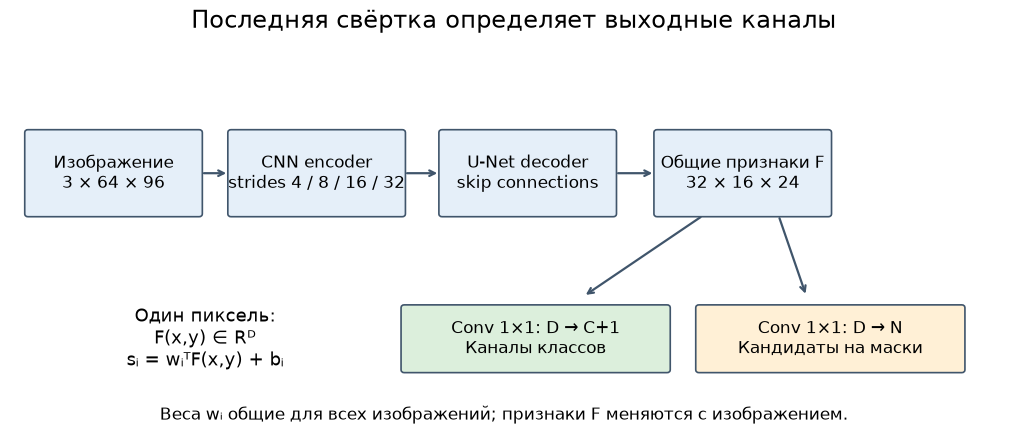

In [10]:
def show_dense_architecture():
    figure, axis = diagram_canvas("Последняя свёртка определяет выходные каналы")
    for x, label in [(1.1, "Изображение\n3 × 64 × 96"), (3.65, "CNN encoder\nstrides 4 / 8 / 16 / 32"),
                     (6.3, "U-Net decoder\nskip connections"), (9.0, "Общие признаки F\n32 × 16 × 24")]:
        diagram_box(axis, (x, 3.4), label, width=2.15, height=1.05)
    for start, end in [(2.2, 2.55), (4.75, 5.2), (7.4, 7.9)]:
        diagram_arrow(axis, (start, 3.4), (end, 3.4))
    diagram_box(axis, (6.4, 1.25), "Conv 1×1: D → C+1\nКаналы классов", width=3.3, color="#dcefdc")
    diagram_box(axis, (10.1, 1.25), "Conv 1×1: D → N\nКандидаты на маски", width=3.3, color="#fff0d6")
    diagram_arrow(axis, (8.5, 2.85), (7.0, 1.8))
    diagram_arrow(axis, (9.45, 2.85), (9.8, 1.8))
    axis.text(2.25, 1.25, "Один пиксель:\nF(x,y) ∈ Rᴰ\nsᵢ = wᵢᵀF(x,y) + bᵢ", ha="center", va="center", fontsize=13)
    axis.text(6, 0.2, "Веса wᵢ общие для всех изображений; признаки F меняются с изображением.", ha="center", fontsize=12)
    finish_visual(figure, "01b_dense_head")


show_dense_architecture()

## 2. Сто масок без transformer

`Conv2d(D, N, 1)` выдаёт $N$ кандидатов на instance-маски. Номер канала не задаёт класс или номер объекта в разметке.

Для классификации кандидата усредним признаки с весами его мягкой маски:

$$m_i(x,y)=\sigma(w_i^\top F(I,x,y)),\qquad
z_i=\frac{\sum_{x,y}m_i(x,y)F(I,x,y)}{\max(\sum_{x,y}m_i(x,y),\varepsilon)}.$$

Общая classification head предсказывает по $z_i$ класс или `no-object`. И маски, и классы зависят от изображения. Градиент classification loss проходит также через веса pooling — предсказанную маску.

Mask pooling нужен, чтобы два кандидата могли получить разные классы на одном изображении. Один общий global pooling дал бы обоим одинаковый вектор. Это проверим на двух областях с разными признаками.

In [11]:
def pool_mask_features(pixels, mask_logits):
    weights = mask_logits.sigmoid().flatten(2)
    features = pixels.flatten(2)
    pooled = torch.einsum("bns,bds->bnd", weights, features)
    return pooled / weights.sum(-1, keepdim=True).clamp_min(1e-6)


class ConvSetSegmenter(nn.Module):
    def __init__(self, num_classes=2, dim=32, num_queries=100, backbone="tiny", pretrained=False):
        super().__init__()
        self.num_classes = num_classes
        self.num_queries = num_queries
        self.pixels = UNetPixelDecoder(dim, backbone, pretrained)
        self.mask_head = nn.Conv2d(dim, num_queries, kernel_size=1, bias=False)
        self.classes = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, num_classes + 1))

    def forward(self, images):
        pixels = self.pixels(images)["mask_features"]
        masks = self.mask_head(pixels)
        pooled = pool_mask_features(pixels, masks)
        return {"pred_masks": masks, "pred_logits": self.classes(pooled), "aux_outputs": []}

### Как сто масок превращаются в набор объектов

Схема вычислений свёрточного baseline. Каждый кандидат имеет маску и распределение классов, включая no-object. Matching назначает кандидатов объектам только при обучении.

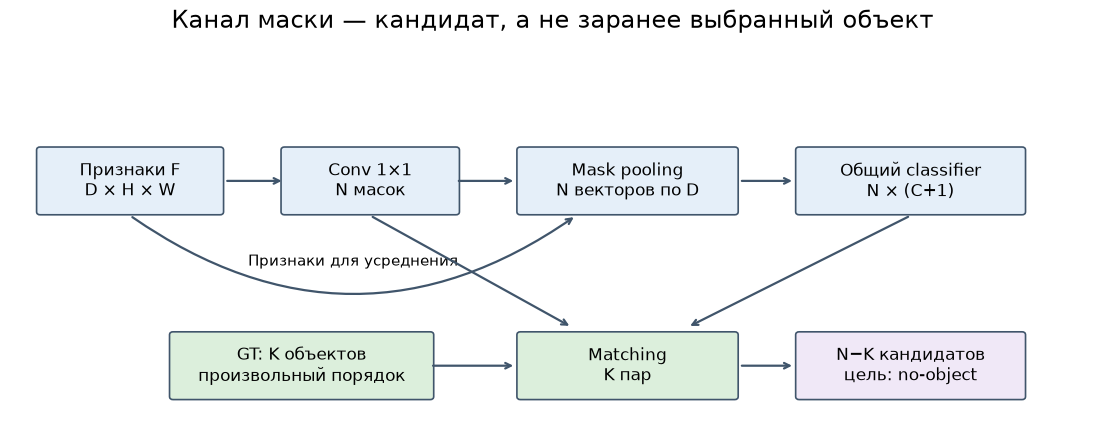

In [12]:
def show_set_prediction_flow():
    figure, axis = diagram_canvas("Канал маски — кандидат, а не заранее выбранный объект", (14, 5))
    diagram_box(axis, (1.2, 3.3), "Признаки F\nD × H × W", width=2.1)
    diagram_box(axis, (4.0, 3.3), "Conv 1×1\nN масок", width=2.0)
    diagram_box(axis, (7.0, 3.3), "Mask pooling\nN векторов по D", width=2.5)
    diagram_box(axis, (10.3, 3.3), "Общий classifier\nN × (C+1)", width=2.6)
    for start, end in [(2.3, 3.0), (5.0, 5.7), (8.3, 8.95)]:
        diagram_arrow(axis, (start, 3.3), (end, 3.3))
    diagram_arrow(axis, (1.2, 2.85), (6.4, 2.85), curve=0.35)
    axis.text(3.8, 2.2, "Признаки для усреднения", ha="center", fontsize=11)
    diagram_box(axis, (3.2, 0.9), "GT: K объектов\nпроизвольный порядок", width=3, color="#dcefdc")
    diagram_box(axis, (7.0, 0.9), "Matching\nK пар", width=2.5, color="#dcefdc")
    diagram_box(axis, (10.3, 0.9), "N−K кандидатов\nцель: no-object", width=2.6, color="#f0e8f7")
    diagram_arrow(axis, (4.7, 0.9), (5.7, 0.9))
    diagram_arrow(axis, (10.3, 2.85), (7.7, 1.4))
    diagram_arrow(axis, (4.0, 2.85), (6.35, 1.4))
    diagram_arrow(axis, (8.3, 0.9), (8.95, 0.9))
    finish_visual(figure, "02a_set_prediction")


show_set_prediction_flow()

### Пример: усреднение по всей картинке и по маске

Возьмём два объекта одинакового размера. Для каждого пикселя первого объекта вручную зададим признаки `[1, 0]`, для второго — `[0, 1]`. В коде первый объект занимает левую половину картинки, второй — правую.

Теперь получим вектор признаков для каждого объекта двумя способами:

- **Усредним по всей картинке.** Получится `[0.5, 0.5]`. Если передать этот вектор для обоих объектов, классификатор получит одинаковые входы.
- **Усредним по маске каждого объекта.** Для первого получится примерно `[1, 0]`, для второго — `[0, 1]`. Теперь классификатор получает разные входы и может предсказать разные классы.

Признаки и маски здесь заданы вручную. Мы проверяем только то, какую информацию сохраняет каждый способ усреднения.

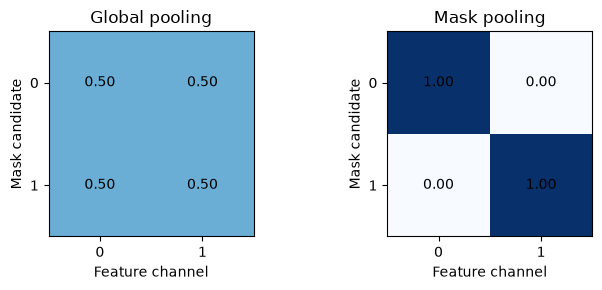

In [13]:
toy_pixels = torch.zeros(1, 2, 4, 8, device=DEVICE)
toy_pixels[:, 0, :, :4] = 1
toy_pixels[:, 1, :, 4:] = 1
toy_masks = 24 * toy_pixels - 12
shared_pool = toy_pixels.mean((2, 3))[:, None].expand(-1, 2, -1)
mask_pool = pool_mask_features(toy_pixels, toy_masks)
torch.testing.assert_close(shared_pool[:, 0], shared_pool[:, 1])
assert (mask_pool[:, 0] - mask_pool[:, 1]).abs().max() > 0.9
figure, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, values, title in zip(axes, [shared_pool[0], mask_pool[0]], ["Global pooling", "Mask pooling"]):
    ax.imshow(values.cpu(), vmin=0, vmax=1, cmap="Blues")
    for row in range(2):
        for column in range(2):
            ax.text(column, row, f"{values[row, column]:.2f}", ha="center", va="center")
    ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="Feature channel", ylabel="Mask candidate", title=title)
figure.tight_layout()
plt.show()

In [14]:
NUM_MASKS = 100
conv_model = ConvSetSegmenter(num_classes=2, dim=32, num_queries=NUM_MASKS).to(DEVICE).eval()
conv_model.pixels.load_state_dict(dense.pixels.state_dict())
with torch.no_grad():
    conv_output = conv_model(images)
    class_delta = (conv_output["pred_logits"][0] - conv_output["pred_logits"][1]).abs().mean()
assert class_delta > 1e-6
print("Masks:", tuple(conv_output["pred_masks"].shape))
print("Classes:", tuple(conv_output["pred_logits"].shape))
print("Class logits differ between images:", float(class_delta))

Masks: (4, 100, 16, 24)
Classes: (4, 100, 3)
Class logits differ between images: 0.09775640815496445


### Matching для каналов масок

Разметка содержит $K\le N$ масок. Выбираем инъективное соответствие между объектами и выходными каналами:

$$\hat\pi=\arg\min_{\pi}\sum_{j=1}^{K}\mathcal C(y_j,\hat y_{\pi(j)}).$$

Для каждой пары «предсказание $i$, объект $j$» считаем стоимость: чем меньше, тем лучше соответствие.

$$\mathcal C_{ij}=2\,[-p_i(c_j)]+5\,\operatorname{BCE}(m_i,t_j)+5\,\mathcal L_{Dice}(m_i,t_j).$$

- **Класс:** насколько кандидат уверен в классе объекта из GT. Один этот член не различит два экземпляра одного класса по их расположению.
- **BCE:** сравнивает вероятность объекта с разметкой в каждом пикселе, учитывая и объект, и фон. Уверенная ошибка даёт большой штраф. Но ошибка на маленьком объекте может слабо повлиять на среднее по всей картинке.
- **Dice:** сравнивает перекрытие относительно суммарной площади масок. Большое число правильно предсказанных фоновых пикселей не улучшает Dice; пропуск маленького объекта остаётся заметным.

$$\mathcal L_{Dice}(m,t)=1-\frac{2\sum mt+1}{\sum m+\sum t+1}.$$

BCE и Dice дополняют друг друга: попиксельные вероятности и относительное перекрытие. Ни один из них отдельно не проверяет класс кандидата. Ниже меняем только размер GT, сохраняя почти нулевое предсказание. При пропуске объекта из четырёх пикселей BCE около 0.008, а Dice loss около 0.88.

Веса 2/5/5 — гиперпараметры из конфигурации Mask2Former, а не требование Hungarian algorithm. При изменении весов может измениться выбранное соответствие. В matching используется $-p(c)$; после выбора пар classification loss использует cross-entropy, то есть $-\log p(c)$.

Можно использовать другую стоимость, например soft IoU. Венгерский алгоритм не требует дифференцируемости. Бинаризация масок перед IoU убирает информацию об уверенности, которая может быть полезна для назначения на ранних шагах.

Matching вычисляется без autograd. Затем градиенты проходят через loss выбранных пар. Незанятые кандидаты получают класс `no-object`.

[Реализация matcher в Mask2Former](https://github.com/facebookresearch/Mask2Former/blob/main/mask2former/modeling/matcher.py) · [Веса losses в статье](https://arxiv.org/html/2112.01527v3#S4.SS1)

| Представление | Метки |
|---|---|
| Dense semantic target | 0 — фон, 1…C — классы |
| Set target | 0…C−1 — классы объектов |
| Class logits | 0…C−1 — классы, C — no-object |

Target пустого изображения содержит ноль масок.

Фиксированное назначение по индексу заставляет модель учить порядок GT, который может быть произвольным. Matching выбирает назначение по содержимому. Он не требует transformer и не гарантирует отсутствие дубликатов на inference.

In [15]:
def pairwise_mask_cost(logits, targets):
    pixels = logits.shape[-1]
    bce = F.softplus(logits).mean(-1, keepdim=True) - logits @ targets.T / pixels
    probabilities = logits.sigmoid()
    intersection = probabilities @ targets.T
    denominator = probabilities.sum(-1, keepdim=True) + targets.sum(-1).unsqueeze(0)
    dice = 1 - (2 * intersection + 1) / (denominator + 1)
    return bce, dice


class HungarianMatcher(nn.Module):
    def __init__(self, class_weight=2, mask_weight=5, dice_weight=5, num_points=0):
        super().__init__()
        self.weights = (class_weight, mask_weight, dice_weight)
        self.num_points = num_points

    @torch.no_grad()
    def cost_matrix(self, logits, masks, target):
        labels, truth = target["labels"], target["masks"]
        if len(labels) > len(logits):
            raise ValueError("More targets than queries: increase num_queries or change the dataset")
        if len(labels) and (labels.min() < 0 or labels.max() >= logits.shape[-1] - 1):
            raise ValueError("Target labels must be in [0, num_classes); no-object is reserved")
        if not len(labels):
            return logits.new_empty((len(logits), 0))
        if self.num_points:
            coordinates = torch.rand(1, self.num_points, 2, device=masks.device)
            predicted = sample_points(masks, coordinates.expand(len(masks), -1, -1))
            actual = sample_points(truth.float(), coordinates.expand(len(truth), -1, -1))
        else:
            predicted = F.interpolate(masks.unsqueeze(1), truth.shape[-2:], mode="bilinear", align_corners=False)
            predicted, actual = predicted.flatten(1), truth.float().flatten(1)
        bce, dice = pairwise_mask_cost(predicted, actual)
        class_cost = -logits.softmax(-1)[:, labels]
        wc, wm, wd = self.weights
        return wc * class_cost + wm * bce + wd * dice

    @torch.no_grad()
    def forward(self, outputs, targets):
        matches = []
        for logits, masks, target in zip(outputs["pred_logits"], outputs["pred_masks"], targets):
            cost = self.cost_matrix(logits, masks, target)
            rows, columns = linear_sum_assignment(cost.cpu().numpy())
            matches.append((
                torch.as_tensor(rows, dtype=torch.long, device=logits.device),
                torch.as_tensor(columns, dtype=torch.long, device=logits.device),
            ))
        return matches


print("side | foreground fraction | BCE | Dice")
for side in (2, 8, 24):
    small_target = torch.zeros(1, 64 * 64, device=DEVICE)
    small_target.view(1, 64, 64)[:, :side, :side] = 1
    missed_logits = torch.full_like(small_target, -7.0)
    bce, dice = pairwise_mask_cost(missed_logits, small_target)
    print(f"{side:4d} | {small_target.mean().item():19.4f} | {bce.item():.4f} | {dice.item():.4f}")

side | foreground fraction | BCE | Dice
   2 |              0.0010 | 0.0077 | 0.8846
   8 |              0.0156 | 0.1103 | 0.9838
  24 |              0.1406 | 0.9853 | 0.9965


### Пропущенный объект: BCE и Dice

Предсказание везде почти нулевое, меняется только размер GT. Сравниваем чувствительность каждого loss к размеру объекта; абсолютные шкалы разных losses сами по себе не сравнивают их полезность.

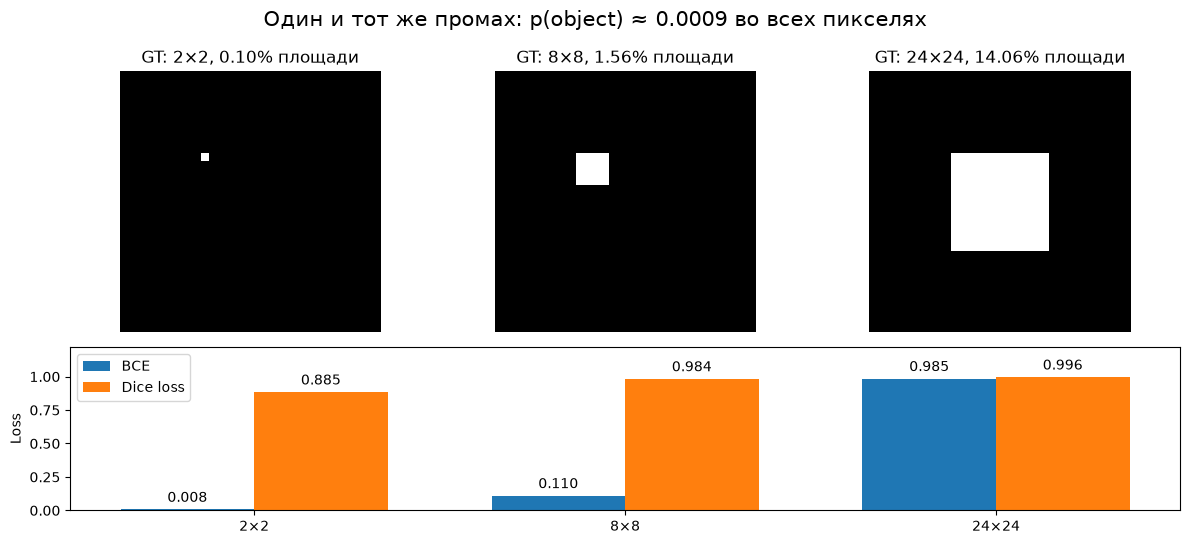

In [16]:
def show_loss_size_effect():
    sizes = [2, 8, 24]
    measured = []
    figure = plt.figure(figsize=(12, 5.5))
    grid = figure.add_gridspec(2, 3, height_ratios=[1.6, 1])
    for index, side in enumerate(sizes):
        target = torch.zeros(1, 64 * 64)
        target.view(64, 64)[20:20 + side, 20:20 + side] = 1
        logits = torch.full_like(target, -7)
        bce, dice = pairwise_mask_cost(logits, target)
        measured.append([bce.item(), dice.item()])
        axis = figure.add_subplot(grid[0, index])
        axis.imshow(target.view(64, 64), cmap="gray", vmin=0, vmax=1)
        axis.set_title(f"GT: {side}×{side}, {100 * target.mean():.2f}% площади")
        axis.axis("off")
    axis = figure.add_subplot(grid[1, :])
    values = np.array(measured)
    for offset, column, label in [(-0.18, 0, "BCE"), (0.18, 1, "Dice loss")]:
        bars = axis.bar(np.arange(3) + offset, values[:, column], width=0.36, label=label)
        axis.bar_label(bars, fmt="%.3f", padding=3)
    axis.set(xticks=np.arange(3), xticklabels=[f"{s}×{s}" for s in sizes], ylabel="Loss", ylim=(0, 1.22))
    axis.legend(loc="upper left")
    figure.suptitle("Один и тот же промах: p(object) ≈ 0.0009 во всех пикселях", fontsize=15)
    figure.tight_layout()
    finish_visual(figure, "02b_bce_dice")


show_loss_size_effect()

In [17]:
def show_matching(cost, match):
    fig, ax = plt.subplots(figsize=(5, 5))
    matrix = cost.detach().cpu().numpy()
    if matrix.shape[1]:
        fig.colorbar(ax.imshow(matrix, aspect="auto"), ax=ax)
        rows, columns = [value.cpu().numpy() for value in match]
        ax.scatter(columns, rows, facecolors="none", edgecolors="red", s=140)
    ax.set(xlabel="Target instance", ylabel="Mask candidate", title="Matching cost and selected pairs")
    fig.tight_layout()
    return fig

Cost shape: (100, 3) requires_grad: False
Matched channel indices: [34, 38, 96]


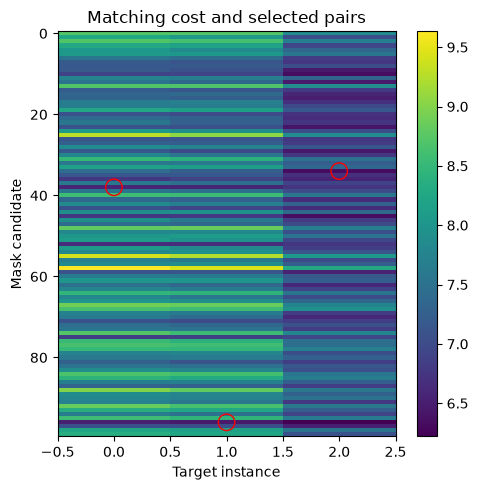

In [18]:
matching_batch = max(range(len(targets)), key=lambda i: len(targets[i]["labels"]))
assert len(targets[matching_batch]["labels"]) >= 2
matcher = HungarianMatcher().to(DEVICE)
cost = matcher.cost_matrix(conv_output["pred_logits"][matching_batch],
                           conv_output["pred_masks"][matching_batch], targets[matching_batch])
matches = matcher(conv_output, targets)
print("Cost shape:", tuple(cost.shape), "requires_grad:", cost.requires_grad)
print("Matched channel indices:", matches[matching_batch][0].tolist())
show_matching(cost, matches[matching_batch])
plt.show()

### Matching и свободные кандидаты

Наглядный пример с пятью вручную заданными предсказаниями: три маски GT переставлены, добавлены дубликат и пустая маска. Стоимость и назначение вычисляет тот же HungarianMatcher.

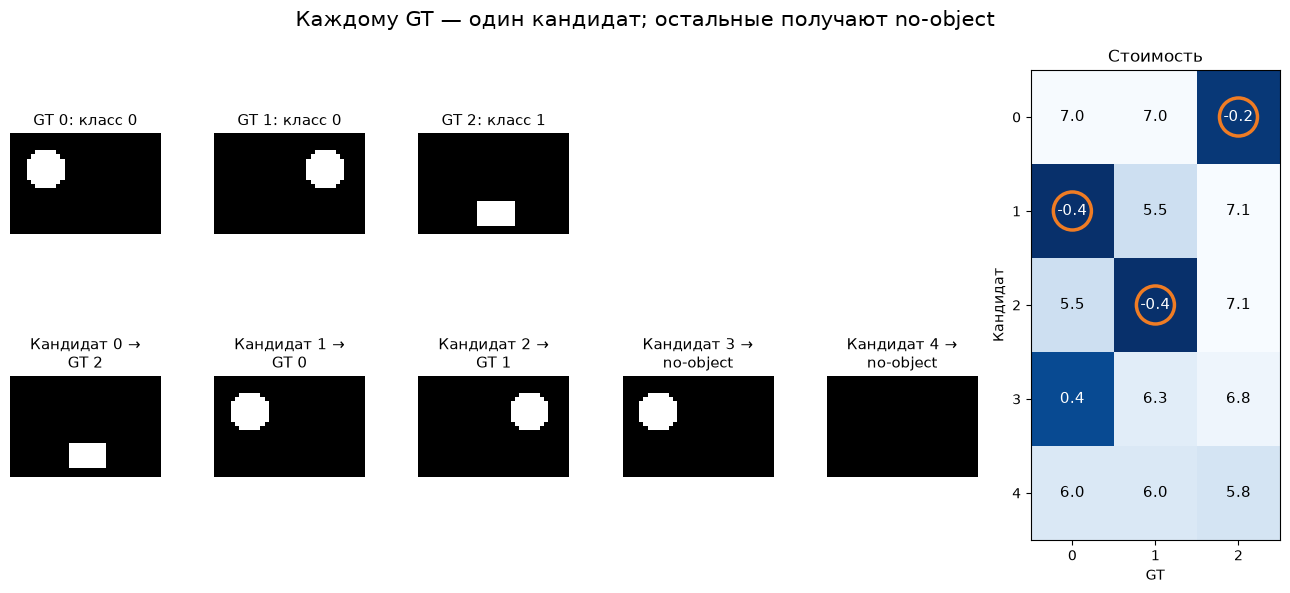

In [19]:
def show_small_matching():
    yy, xx = torch.meshgrid(torch.arange(24), torch.arange(36), indexing="ij")
    gt = torch.stack([((xx - 8) ** 2 + (yy - 8) ** 2 < 25),
                      ((xx - 26) ** 2 + (yy - 8) ** 2 < 25),
                      ((xx > 13) & (xx < 23) & (yy > 15) & (yy < 22))]).float()
    target = {"masks": gt, "labels": torch.tensor([0, 0, 1])}
    candidate_masks = torch.cat([gt[[2, 0, 1]], gt[:1], torch.zeros_like(gt[:1])])
    probabilities = torch.tensor([[.03, .94, .03], [.94, .03, .03], [.94, .03, .03],
                                  [.55, .20, .25], [.05, .05, .90]])
    logits = torch.logit(candidate_masks * .9 + .05)
    output = {"pred_masks": logits[None], "pred_logits": probabilities.log()[None]}
    matcher = HungarianMatcher()
    matrix = matcher.cost_matrix(output["pred_logits"][0], logits, target)
    selected, objects = matcher(output, [target])[0]
    assignment = dict(zip(selected.tolist(), objects.tolist()))
    figure = plt.figure(figsize=(13, 6))
    grid = figure.add_gridspec(2, 6, width_ratios=[1, 1, 1, 1, 1, 1.65])
    for index, mask in enumerate(gt):
        axis = figure.add_subplot(grid[0, index])
        axis.imshow(mask, cmap="gray", vmin=0, vmax=1)
        axis.set_title(f"GT {index}: класс {target['labels'][index]}", fontsize=11)
        axis.axis("off")
    for index, mask in enumerate(candidate_masks):
        axis = figure.add_subplot(grid[1, index])
        axis.imshow(mask, cmap="gray", vmin=0, vmax=1)
        destination = f"GT {assignment[index]}" if index in assignment else "no-object"
        axis.set_title(f"Кандидат {index} →\n{destination}", fontsize=11)
        axis.axis("off")
    axis = figure.add_subplot(grid[:, 5])
    axis.imshow(matrix, cmap="Blues_r", aspect="auto")
    for row in range(5):
        for column in range(3):
            axis.text(column, row, f"{matrix[row, column]:.1f}", ha="center", va="center", fontsize=11,
                      color="white" if matrix[row, column] < matrix.mean() else "black")
    axis.scatter(objects, selected, s=750, facecolors="none", edgecolors="#ef7c24", linewidths=2.5)
    axis.set(xticks=range(3), yticks=range(5), xlabel="GT", ylabel="Кандидат", title="Стоимость")
    figure.suptitle("Каждому GT — один кандидат; остальные получают no-object", fontsize=15)
    figure.tight_layout()
    finish_visual(figure, "02c_matching")


show_small_matching()

### Loss после matching

Matching уже выбрал пары. Теперь считаем loss, по которому будут обновляться веса модели.

Если из 100 кандидатов три сопоставлены объектам:

- Для этих трёх считаем classification loss по классу объекта, а также BCE и Dice по его маске.
- Остальные 97 учим предсказывать класс `no-object`. Отдельный mask loss для них не считаем.

`No-object` означает, что кандидат не соответствует ни одному объекту. Он позволяет модели выдать меньше объектов, чем у неё выходных слотов. Свободных кандидатов обычно больше, поэтому их вес в classification loss уменьшаем до 0.1.

Для classification теперь используется cross-entropy (`−log p`), а в стоимости matching было `−p`. Веса 2/5/5 применяются к classification, BCE и Dice соответственно.

Позже `aux_outputs` добавит такие же losses для промежуточных предсказаний decoder.

In [20]:
class SetCriterion(nn.Module):
    def __init__(self, num_classes=2, no_object_weight=0.1, num_points=0,
                 class_weight=2, mask_weight=5, dice_weight=5):
        super().__init__()
        if num_points < 0:
            raise ValueError("num_points must be nonnegative; zero means dense loss")
        self.num_classes = num_classes
        self.num_points = num_points
        self.weights = (class_weight, mask_weight, dice_weight)
        self.matcher = HungarianMatcher(class_weight, mask_weight, dice_weight, num_points)
        class_weights = torch.ones(num_classes + 1)
        class_weights[-1] = no_object_weight
        self.register_buffer("class_weights", class_weights)

    def single_loss(self, outputs, targets):
        logits, masks = outputs["pred_logits"], outputs["pred_masks"]
        matches = self.matcher(outputs, targets)
        classes = torch.full(logits.shape[:2], self.num_classes, dtype=torch.long, device=logits.device)
        loss_bce, loss_dice = masks.sum() * 0, masks.sum() * 0
        count = 0
        for batch, (rows, columns) in enumerate(matches):
            classes[batch, rows] = targets[batch]["labels"][columns]
            if not len(rows):
                continue
            predicted = masks[batch, rows]
            actual = targets[batch]["masks"][columns].float()
            if self.num_points:
                coordinates = uncertain_points(predicted, self.num_points)
                predicted = sample_points(predicted, coordinates)
                actual = sample_points(actual, coordinates)
            else:
                predicted = F.interpolate(predicted.unsqueeze(1), actual.shape[-2:], mode="bilinear", align_corners=False)
                predicted, actual = predicted.flatten(1), actual.flatten(1)
            loss_bce = loss_bce + F.binary_cross_entropy_with_logits(predicted, actual, reduction="none").mean(-1).sum()
            probabilities = predicted.sigmoid()
            intersection = (probabilities * actual).sum(-1)
            denominator = probabilities.sum(-1) + actual.sum(-1)
            loss_dice = loss_dice + (1 - (2 * intersection + 1) / (denominator + 1)).sum()
            count += len(rows)
        return {
            "class": F.cross_entropy(logits.transpose(1, 2), classes, weight=self.class_weights),
            "mask": loss_bce / max(count, 1),
            "dice": loss_dice / max(count, 1),
        }

    def weighted(self, losses):
        return sum(weight * losses[key] for weight, key in zip(self.weights, ("class", "mask", "dice")))

    def forward(self, outputs, targets):
        if len(targets) != len(outputs["pred_logits"]):
            raise ValueError("One target dictionary is required per image")
        losses = self.single_loss(outputs, targets)
        auxiliary = outputs["pred_masks"].sum() * 0
        for intermediate in outputs.get("aux_outputs", []):
            auxiliary = auxiliary + self.weighted(self.single_loss(intermediate, targets))
        return {**losses, "auxiliary": auxiliary, "loss": self.weighted(losses) + auxiliary}


criterion = SetCriterion(num_classes=2).to(DEVICE)

Для проверки веса `no-object` фиксируем 100 кандидатов, из которых заняты два. Сравниваем суммарный модуль градиента от занятых и свободных кандидатов при весах 1 и 0.1.

Смотрим на отношение этих вкладов: weighted mean также меняет знаменатель loss. Малый вес уменьшает относительное влияние свободных слотов; оптимальное значение зависит от данных.

In [21]:
assigned_classes = torch.full((100,), 2, dtype=torch.long, device=DEVICE)
assigned_classes[:2] = torch.tensor([0, 1], device=DEVICE)
print("no-object weight | object gradient | no-object gradient | ratio")
for weight in (1.0, 0.1):
    class_logits = torch.zeros(100, 3, device=DEVICE, requires_grad=True)
    class_weights = torch.tensor([1.0, 1.0, weight], device=DEVICE)
    loss = F.cross_entropy(class_logits, assigned_classes, weight=class_weights)
    gradient = torch.autograd.grad(loss, class_logits)[0].abs().sum(-1)
    object_mass, empty_mass = gradient[:2].sum(), gradient[2:].sum()
    print(f"{weight:16.1f} | {object_mass.item():15.4f} | {empty_mass.item():18.4f} | {(empty_mass / object_mass).item():.1f}")

no-object weight | object gradient | no-object gradient | ratio
             1.0 |          0.0267 |             1.3067 | 49.0
             0.1 |          0.2260 |             1.1073 | 4.9


### Кто определяет classification gradient

Два занятых и 98 свободных слотов, одинаковые нулевые logits. Показываем сумму модулей градиентов каждой группы и их отношение.

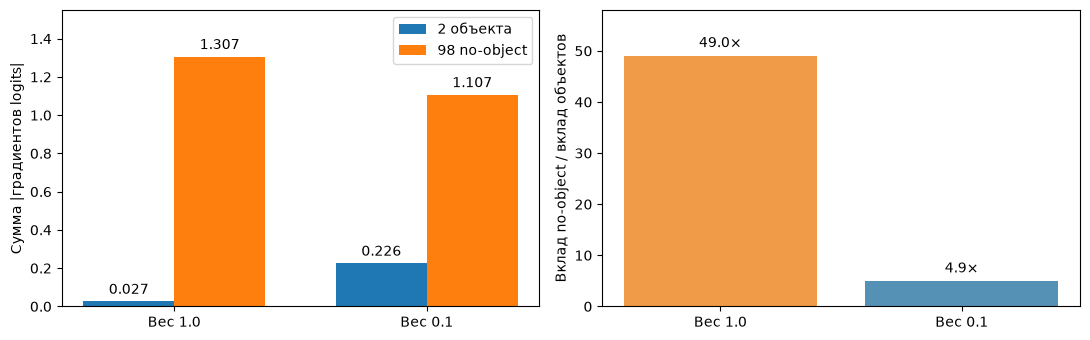

In [22]:
def show_no_object_gradient():
    target = torch.full((100,), 2, dtype=torch.long)
    target[:2] = torch.tensor([0, 1])
    values = []
    for weight in (1.0, 0.1):
        logits = torch.zeros(100, 3, requires_grad=True)
        loss = F.cross_entropy(logits, target, weight=torch.tensor([1., 1., weight]))
        gradient = torch.autograd.grad(loss, logits)[0].abs().sum(-1)
        values.append([gradient[:2].sum().item(), gradient[2:].sum().item()])
    figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    values = np.array(values)
    for offset, column, name in [(-.18, 0, "2 объекта"), (.18, 1, "98 no-object")]:
        bars = axes[0].bar(np.arange(2) + offset, values[:, column], width=.36, label=name)
        axes[0].bar_label(bars, fmt="%.3f", padding=3)
    axes[0].set(xticks=[0, 1], xticklabels=["Вес 1.0", "Вес 0.1"], ylabel="Сумма |градиентов logits|", ylim=(0, 1.55))
    axes[0].legend()
    ratios = values[:, 1] / values[:, 0]
    bars = axes[1].bar([0, 1], ratios, color=["#ef9b47", "#5491b5"])
    axes[1].bar_label(bars, fmt="%.1f×", padding=4)
    axes[1].set(xticks=[0, 1], xticklabels=["Вес 1.0", "Вес 0.1"], ylabel="Вклад no-object / вклад объектов", ylim=(0, 58))
    figure.tight_layout()
    finish_visual(figure, "02d_no_object")


show_no_object_gradient()

### Перестановка GT

Переставим разметку внутри изображения. Loss с matching должен сохраниться. Для сравнения посчитаем BCE при фиксированном назначении масок по индексу.

Контроль: выход модели не меняем. Переставляем только строки разметки. Сравнение с назначением по индексу показывает, какую зависимость от порядка убирает matching.

In [23]:
permuted = [{key: value.flip(0) for key, value in t.items()} for t in targets]
loss_original = criterion(conv_output, targets)["loss"]
loss_permuted = criterion(conv_output, permuted)["loss"]
torch.testing.assert_close(loss_original, loss_permuted)
print("Set loss, original / permuted:", float(loss_original), float(loss_permuted))

truth = torch.zeros(2, 8, 8, device=DEVICE)
truth[0, :, :4] = 1
truth[1, :, 4:] = 1
prediction = 8 * (2 * truth - 1)
fixed_original = F.binary_cross_entropy_with_logits(prediction, truth)
fixed_permuted = F.binary_cross_entropy_with_logits(prediction, truth.flip(0))
print("Fixed assignment BCE, original / permuted:", float(fixed_original), float(fixed_permuted))

Set loss, original / permuted: 8.590059280395508 8.590059280395508
Fixed assignment BCE, original / permuted: 0.00033554984838701785 8.000335693359375


In [24]:
conv_model.train()
conv_model.zero_grad(set_to_none=True)
conv_losses = criterion(conv_model(images), targets)
conv_losses["loss"].backward()
print({key: round(float(value.detach()), 4) for key, value in conv_losses.items()})
for name, parameter in [("Mask filters", conv_model.mask_head.weight),
                        ("Classifier", conv_model.classes[-1].weight),
                        ("Encoder", conv_model.pixels.encoder.stem[0].weight)]:
    assert torch.isfinite(parameter.grad).all() and parameter.grad.norm() > 0
    print(name, "gradient norm:", float(parameter.grad.norm()))

empty_targets = [{"labels": torch.empty(0, dtype=torch.long, device=DEVICE),
                  "masks": torch.empty(0, *images.shape[-2:], device=DEVICE)} for _ in images]
empty_losses = criterion(conv_model(images), empty_targets)
assert empty_losses["mask"].item() == 0 and empty_losses["dice"].item() == 0
print("Empty images: class loss remains =", float(empty_losses["class"].detach()))

{'class': 0.8834, 'mask': 0.4987, 'dice': 0.866, 'auxiliary': -0.0, 'loss': 8.5901}
Mask filters gradient norm: 1.6013423204421997
Classifier gradient norm: 6.306493759155273
Encoder gradient norm: 3.1807212829589844
Empty images: class loss remains = 0.7961176037788391


### Semantic и instance targets

Для semantic segmentation объединяем экземпляры класса в одну маску, в том числе несвязную. Для instance segmentation сохраняем отдельную маску каждого объекта.

In [25]:
def merge_instances_by_class(target):
    labels = target["labels"].unique(sorted=True)
    masks = [target["masks"][target["labels"] == label].amax(0) for label in labels]
    return {"labels": labels, "masks": torch.stack(masks) if masks else target["masks"].clone()}

In [26]:
two_instances = {"labels": torch.tensor([0, 0], device=DEVICE), "masks": truth}
one_class_mask = merge_instances_by_class(two_instances)
print("Instance targets:", tuple(two_instances["masks"].shape))
print("Semantic set targets:", tuple(one_class_mask["masks"].shape))

Instance targets: (2, 8, 8)
Semantic set targets: (1, 8, 8)


## 3. Queries: от фиксированного фильтра к обновляемому состоянию

Свёрточный baseline уже предсказывает набор объектов. Признаки $F(I)$ зависят от изображения, а фильтры масок $w_i$ фиксированы после обучения:

$$\ell_i(x,y)=w_i^\top F(I,x,y).$$

Что, если строить **сам фильтр маски по текущему изображению**?

$$\ell_i(x,y)=e_i(I)^\top F(I,x,y).$$

Для этого заведём каждому кандидату состояние $q_i$. Начальные состояния — обучаемые параметры, общие для всех изображений. Decoder читает изображение и обновляет состояния; из них MLP строит фильтры $e_i(I)$. Следующий слой может обновить того же кандидата ещё раз.

Общая карта пиксельных признаков остаётся. Set prediction и matching у нас уже есть. Проверяем, что даёт новый способ вычисления масок.

### Фиксированные embeddings ещё ничего не меняют

Берём веса свёртки $1\times1$ без bias и вычисляем те же 100 масок через dot product. Если queries не читают изображение, MLP над ними также выдаёт фиксированный набор фильтров.

In [27]:
with torch.no_grad():
    conv_pixels = conv_model.pixels(images)["mask_features"]
    fixed_embeddings = conv_model.mask_head.weight[:, :, 0, 0]
    masks_from_embeddings = torch.einsum("nd,bdhw->bnhw", fixed_embeddings, conv_pixels)
    masks_from_conv = conv_model.mask_head(conv_pixels)
    torch.testing.assert_close(masks_from_embeddings, masks_from_conv)
print("Fixed embeddings:", tuple(fixed_embeddings.shape))
print("Maximum difference:", float((masks_from_embeddings - masks_from_conv).abs().max()))

Fixed embeddings: (100, 32)
Maximum difference: 0.0


### Где появляется зависимость фильтра от изображения

В обеих моделях F зависит от изображения. В query-модели дополнительный путь от F обновляет состояние кандидата и меняет сам фильтр маски.

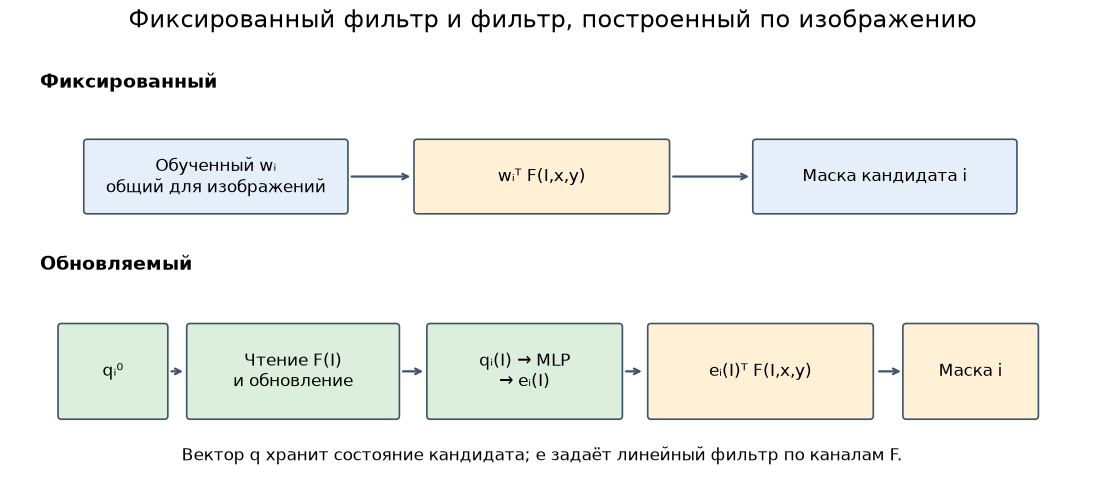

In [28]:
def show_dynamic_filter():
    figure, axis = diagram_canvas("Фиксированный фильтр и фильтр, построенный по изображению", (14, 5.5))
    axis.text(.15, 4.55, "Фиксированный", fontsize=14, weight="bold")
    diagram_box(axis, (2.2, 3.5), "Обученный wᵢ\nобщий для изображений", width=3)
    diagram_box(axis, (6.0, 3.5), "wᵢᵀ F(I,x,y)", width=2.9, color="#fff0d6")
    diagram_box(axis, (10, 3.5), "Маска кандидата i", width=3)
    diagram_arrow(axis, (3.75, 3.5), (4.5, 3.5))
    diagram_arrow(axis, (7.5, 3.5), (8.45, 3.5))
    axis.text(.15, 2.4, "Обновляемый", fontsize=14, weight="bold")
    for x, label, width in [(1.0, "qᵢ⁰", 1.2), (3.1, "Чтение F(I)\nи обновление", 2.4),
                            (5.8, "qᵢ(I) → MLP\n→ eᵢ(I)", 2.2), (8.55, "eᵢ(I)ᵀ F(I,x,y)", 2.55), (11, "Маска i", 1.5)]:
        diagram_box(axis, (x, 1.2), label, width=width, height=1.05,
                    color="#dcefdc" if x < 7 else "#fff0d6")
    for start, end in [(1.65, 1.85), (4.35, 4.65), (6.95, 7.2), (9.9, 10.22)]:
        diagram_arrow(axis, (start, 1.2), (end, 1.2))
    axis.text(6, .15, "Вектор q хранит состояние кандидата; e задаёт линейный фильтр по каналам F.", ha="center", fontsize=12)
    finish_visual(figure, "03a_dynamic_filter")


show_dynamic_filter()

### Одно обновление query

Сначала одна голова attention без обучаемых проекций, координат и нормализации. В роли начальных queries используем уже имеющиеся фильтры масок. Каждый query сравнивается с пространственными признаками, получает веса чтения и собирает с ними новый вектор:

$$A=\operatorname{softmax}_{HW}(QF^\top/\sqrt D),\qquad Q'=Q+AF.$$

В этом коротком примере $e_i=q'_i$. В полной модели появятся проекции Q/K/V и MLP для mask embeddings. Это показ вычисления; качество масок необученной модели здесь не оцениваем.

In [29]:
with torch.no_grad():
    memory = conv_pixels.flatten(2).transpose(1, 2)
    q0 = fixed_embeddings.unsqueeze(0).expand(len(images), -1, -1)
    read_weights = (q0 @ memory.transpose(1, 2) / math.sqrt(q0.shape[-1])).softmax(-1)
    q1 = q0 + read_weights @ memory
    updated_masks = torch.einsum("bnd,bdhw->bnhw", q1, conv_pixels)
torch.testing.assert_close(read_weights.sum(-1), torch.ones_like(read_weights[..., 0]))
for name, value in [("Memory [B, HW, D]", memory), ("Queries [B, N, D]", q1),
                    ("Read weights [B, N, HW]", read_weights), ("Masks [B, N, H, W]", updated_masks)]:
    print(name, tuple(value.shape))

Memory [B, HW, D] (4, 384, 32)
Queries [B, N, D] (4, 100, 32)
Read weights [B, N, HW] (4, 100, 384)
Masks [B, N, H, W] (4, 100, 16, 24)


### Softmax нормируется отдельно для каждого query

Ручной пример: два запроса читают четыре memory-токена. Проекций и обучения нет. Два query могут дать наибольший вес одной позиции: cross-attention не распределяет позиции между кандидатами взаимоисключающим образом.

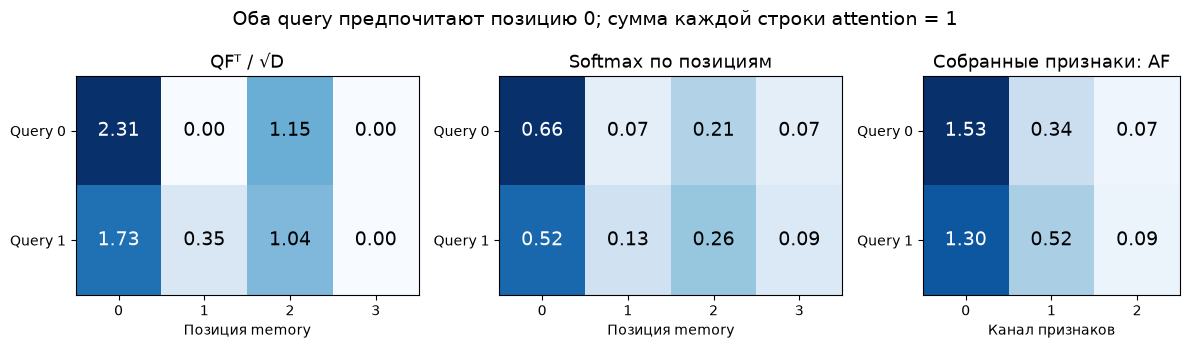

In [30]:
def show_attention_rows():
    q = torch.tensor([[2., 0., 0.], [1.5, .3, 0.]])
    memory = torch.tensor([[2., 0., 0.], [0., 2., 0.], [1., 1., 0.], [0., 0., 1.]])
    scores = q @ memory.T / math.sqrt(3)
    weights = scores.softmax(-1)
    update = weights @ memory
    figure, axes = plt.subplots(1, 3, figsize=(12, 3.5), gridspec_kw={"width_ratios": [4, 4, 3]})
    for axis, data, title in zip(axes, [scores, weights, update], ["QFᵀ / √D", "Softmax по позициям", "Собранные признаки: AF"]):
        axis.imshow(data, cmap="Blues", aspect="auto", vmin=0)
        for row in range(data.shape[0]):
            for column in range(data.shape[1]):
                axis.text(column, row, f"{data[row, column]:.2f}", ha="center", va="center", fontsize=14,
                          color="white" if data[row, column] > .6 * data.max() else "black")
        axis.set(yticks=[0, 1], yticklabels=["Query 0", "Query 1"], xticks=range(data.shape[1]))
        axis.set_title(title, fontsize=13)
        axis.set_xlabel("Позиция memory" if data.shape[1] == 4 else "Канал признаков")
    figure.suptitle("Оба query предпочитают позицию 0; сумма каждой строки attention = 1", fontsize=14)
    figure.tight_layout()
    finish_visual(figure, "03b_attention_rows")


show_attention_rows()

### Состояние кандидата → маска и класс

`MaskHead` строит mask embedding из query и умножает его на pixel features. Класс обычно предсказывается из того же query.

Оставим также режим `classification="mask_pool"`: класс читается по готовой маске, как в baseline. Он понадобится для сравнения фиксированных и динамических фильтров с одинаковым способом классификации.

In [31]:
class MaskHead(nn.Module):
    def __init__(self, dim, num_classes, classification="query"):
        super().__init__()
        if classification not in ("query", "mask_pool"):
            raise ValueError("Unknown classification source")
        self.classification = classification
        self.pool_norm = nn.LayerNorm(dim) if classification == "mask_pool" else None
        self.norm = nn.LayerNorm(dim)
        self.classes = nn.Linear(dim, num_classes + 1)
        self.mask_embedding = nn.Sequential(nn.Linear(dim, dim), nn.ReLU(), nn.Linear(dim, dim))

    def forward(self, queries, pixels):
        queries = self.norm(queries)
        embeddings = self.mask_embedding(queries)
        masks = torch.einsum("bqd,bdhw->bqhw", embeddings, pixels)
        class_features = self.pool_norm(pool_mask_features(pixels, masks)) if self.classification == "mask_pool" else queries
        return {"pred_logits": self.classes(class_features), "mask_embeddings": embeddings, "pred_masks": masks}

### Несколько обновлений

**Cross-attention** читает пространственные признаки для каждого кандидата. При фиксированной memory кандидаты вычисляются независимо. **Self-attention** добавляет обмен между кандидатами. **FFN** преобразует состояние каждого кандидата отдельно.

Query features — текущее состояние кандидата. Query positions — отдельные обучаемые параметры слотов, которые добавляются при вычислении attention. Пространственные позиции задают координаты memory-токенов. В коде: cross-attention → self-attention → FFN, residual connections и LayerNorm.

Начальная маска вычисляется до первого слоя, затем маски пересчитываются после каждого обновления. В следующих разделах включим промежуточные losses, ограничение attention маской и несколько масштабов. Здесь используем global attention и loss только на последнем выходе.

In [32]:
def position_encoding(features):
    _, dim, height, width = features.shape
    if dim % 4:
        raise ValueError("Feature dimension must be divisible by 4")
    y = (torch.arange(height, device=features.device) + 0.5) / height * (2 * math.pi)
    x = (torch.arange(width, device=features.device) + 0.5) / width * (2 * math.pi)
    frequency = 10000 ** (torch.arange(dim // 4, device=features.device) / (dim // 4))
    yy, xx = torch.meshgrid(y, x, indexing="ij")
    px, py = xx[..., None] / frequency, yy[..., None] / frequency
    position = torch.cat([px.sin(), px.cos(), py.sin(), py.cos()], dim=-1)
    return position.reshape(1, height * width, dim).to(features.dtype)


class QueryDecoderLayer(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.cross_attention = nn.MultiheadAttention(dim, heads, dropout=0, batch_first=True)
        self.self_attention = nn.MultiheadAttention(dim, heads, dropout=0, batch_first=True)
        self.ffn = nn.Sequential(nn.Linear(dim, 4 * dim), nn.ReLU(), nn.Linear(4 * dim, dim))
        self.norms = nn.ModuleList([nn.LayerNorm(dim) for _ in range(3)])

    def forward(self, queries, query_position, memory, memory_position, blocked=None, trace=False):
        update, cross_weights = self.cross_attention(
            queries + query_position, memory + memory_position, memory,
            attn_mask=blocked, need_weights=trace, average_attn_weights=False,
        )
        queries = self.norms[0](queries + update)
        update, self_weights = self.self_attention(
            queries + query_position, queries + query_position, queries,
            need_weights=trace, average_attn_weights=False,
        )
        queries = self.norms[1](queries + update)
        queries = self.norms[2](queries + self.ffn(queries))
        return queries, cross_weights, self_weights

In [33]:
class QuerySegmenter(nn.Module):
    def __init__(
        self, num_classes=2, dim=32, num_queries=8, heads=4, layers=3,
        masked_attention=False, multiscale=False, auxiliary_loss=True,
        backbone="tiny", pretrained=False, classification="query",
    ):
        super().__init__()
        if dim % 4 or dim % heads or num_queries < 1 or layers < 0:
            raise ValueError("Check dim, heads, num_queries and layers")
        self.num_classes = num_classes
        self.num_queries = num_queries
        self.heads = heads
        self.masked_attention = masked_attention
        self.multiscale = multiscale
        self.auxiliary_loss = auxiliary_loss
        self.pixels = UNetPixelDecoder(dim, backbone, pretrained)
        self.query_features = nn.Embedding(num_queries, dim)
        self.query_position = nn.Embedding(num_queries, dim)
        self.level_position = nn.Embedding(3, dim)
        self.decoder = nn.ModuleList([QueryDecoderLayer(dim, heads) for _ in range(layers)])
        self.head = MaskHead(dim, num_classes, classification)

    def forward(self, images, return_trace=False):
        features = self.pixels(images)
        queries = self.query_features.weight.unsqueeze(0).expand(images.shape[0], -1, -1)
        query_position = self.query_position.weight.unsqueeze(0)
        predictions = [self.head(queries, features["mask_features"])]
        traces = []
        for index, layer in enumerate(self.decoder):
            level = index % 3 if self.multiscale else 0
            spatial = features["memories"][level]
            memory = spatial.flatten(2).transpose(1, 2) + self.level_position.weight[level]
            blocked = None
            if self.masked_attention:
                blocked, allowed, empty = attention_mask(predictions[-1]["pred_masks"], spatial.shape[-2:], self.heads)
            elif return_trace:
                shape = (images.shape[0], self.num_queries, spatial.shape[-2] * spatial.shape[-1])
                allowed = torch.ones(shape, dtype=torch.bool, device=images.device)
                empty = torch.zeros(shape[:2], dtype=torch.bool, device=images.device)
            queries, cross_weights, self_weights = layer(
                queries, query_position, memory, position_encoding(spatial), blocked, return_trace,
            )
            predictions.append(self.head(queries, features["mask_features"]))
            if return_trace:
                traces.append({
                    "level": level, "size": spatial.shape[-2:],
                    "allowed": allowed.detach(), "empty_fallback": empty.detach(),
                    "cross_attention": cross_weights.detach(), "self_attention": self_weights.detach(),
                })
        output = dict(predictions[-1])
        output["aux_outputs"] = predictions[:-1] if self.auxiliary_loss else []
        if return_trace:
            output["trace"] = traces
            output["stages"] = [{k: v.detach() for k, v in p.items()} for p in predictions]
        return output

### Обучение для следующих опытов

Ниже функции обучения и метрик, используемые до конца ноутбука. В первом опыте используем `global_no_aux`, seed 42: 32 тренировочных изображения, 200 шагов, 8 кандидатов при максимуме в три объекта. Затем проверяем модель на 32 новых изображениях.

Все варианты используют одинаковые split, начальные веса pixel decoder, optimizer и порядок batch для каждого seed. Модели и результаты остаются в памяти; повторный вызов не запускает обучение заново. После изменения конфигурации выполните её ячейку и все следующие ячейки.

In [34]:
def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()


def train_steps(model, loader, criterion, steps=80, learning_rate=0.001, device="cpu", log_every=20):
    device = torch.device(device)
    model.to(device).train()
    if criterion is not None:
        criterion.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.0001)
    iterator = iter(loader)
    history = []
    for step in range(1, steps + 1):
        try:
            images, targets = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            images, targets = next(iterator)
        images, targets = images.to(device), targets_to_device(targets, device)
        synchronize(device)
        started = time.perf_counter()
        optimizer.zero_grad(set_to_none=True)
        output = model(images)
        losses = {"loss": F.cross_entropy(output, semantic_targets(targets))} if criterion is None else criterion(output, targets)
        if not torch.isfinite(losses["loss"]):
            raise FloatingPointError(f"Non-finite loss at step {step}")
        losses["loss"].backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        synchronize(device)
        row = {key: float(value.detach()) for key, value in losses.items()}
        row.update(step=step, seconds=time.perf_counter() - started)
        history.append(row)
        if log_every and (step == 1 or step % log_every == 0 or step == steps):
            print(f"step={step:4d} loss={row['loss']:.4f}")
    return history

mIoU включает фон. Instance precision/recall считаются при IoU ≥ 0.5 и фиксированном score threshold. При пересечении предсказаний semantic-постобработка отдаёт пиксель более уверенному объекту.

In [35]:
def predict_instances(output, size, score_threshold=0.4, mask_threshold=0.5):
    results = []
    probabilities = output["pred_logits"].softmax(-1)
    masks = F.interpolate(output["pred_masks"], size=size, mode="bilinear", align_corners=False).sigmoid()
    for classes, mask in zip(probabilities, masks):
        scores, labels = classes.max(-1)
        keep = (labels != classes.shape[-1] - 1) & (scores >= score_threshold)
        binary = mask > mask_threshold
        keep = keep & binary.flatten(1).any(-1)
        results.append({"labels": labels[keep], "masks": binary[keep], "scores": scores[keep]})
    return results


def instances_to_semantic(predictions, size):
    result = []
    for predicted in predictions:
        semantic = torch.zeros(size, dtype=torch.long, device=predicted["masks"].device)
        for index in predicted["scores"].argsort():
            semantic[predicted["masks"][index]] = predicted["labels"][index] + 1
        result.append(semantic)
    return torch.stack(result)


@torch.no_grad()
def evaluate(model, loader, num_classes, device="cpu", score_threshold=0.4):
    device = torch.device(device)
    model.to(device).eval()
    confusion = torch.zeros(num_classes + 1, num_classes + 1, dtype=torch.long)
    instance_tp, instance_fp, instance_fn = 0, 0, 0
    is_dense = isinstance(model, DenseSegmenter)
    for images, targets in loader:
        images = images.to(device)
        output = model(images)
        if is_dense:
            semantic = output.argmax(1).cpu()
        else:
            predictions = predict_instances(output, images.shape[-2:], score_threshold)
            semantic = instances_to_semantic(predictions, images.shape[-2:]).cpu()
            for predicted, target in zip(predictions, targets):
                pm = predicted["masks"].cpu().flatten(1).float()
                tm = target["masks"].flatten(1).float()
                if len(pm) and len(tm):
                    intersection = pm @ tm.T
                    union = pm.sum(1)[:, None] + tm.sum(1)[None, :] - intersection
                    same_class = predicted["labels"].cpu()[:, None] == target["labels"][None, :]
                    eligible = (intersection / union.clamp_min(1) >= 0.5) & same_class
                    rows, columns = linear_sum_assignment(-eligible.numpy().astype(float))
                    matched = int(eligible[rows, columns].sum())
                else:
                    matched = 0
                instance_tp += matched
                instance_fp += len(pm) - matched
                instance_fn += len(tm) - matched
        truth = semantic_targets(targets).cpu()
        pairs = truth.flatten() * (num_classes + 1) + semantic.flatten()
        confusion += torch.bincount(pairs, minlength=(num_classes + 1) ** 2).reshape_as(confusion)
    intersection = confusion.diag().float()
    union = confusion.sum(0) + confusion.sum(1) - intersection
    present = union > 0
    iou = intersection / union.clamp_min(1)
    metrics = {"semantic_miou": float(iou[present].mean()), "per_class_iou": iou.tolist()}
    if not is_dense:
        metrics.update(
            instance_precision_50=instance_tp / max(instance_tp + instance_fp, 1),
            instance_recall_50=instance_tp / max(instance_tp + instance_fn, 1),
            instance_tp=instance_tp, instance_fp=instance_fp, instance_fn=instance_fn,
        )
    return metrics

In [36]:
VARIANTS = {
    "conv": {},
    "global_pool": {"masked_attention": False, "multiscale": False, "auxiliary_loss": False, "classification": "mask_pool"},
    "global_no_aux": {"masked_attention": False, "multiscale": False, "auxiliary_loss": False},
    "global": {"masked_attention": False, "multiscale": False, "auxiliary_loss": True},
    "masked": {"masked_attention": True, "multiscale": False, "auxiliary_loss": True},
    "multiscale": {"masked_attention": True, "multiscale": True, "auxiliary_loss": True},
    "no_aux": {"masked_attention": True, "multiscale": True, "auxiliary_loss": False},
    "sampled": {"masked_attention": True, "multiscale": True, "auxiliary_loss": True},
}
MODEL_CONFIG = {"num_classes": 2, "dim": 32, "num_queries": 8, "heads": 4, "layers": 3}
DATA_SEED = 123
SEEDS = (42, 43, 44)
BATCH_SIZE = 4
LEARNING_RATE = 0.001
NUM_POINTS = 256
SCORE_THRESHOLD = 0.4

comparison_train = ShapesDataset(count=32, seed=DATA_SEED)
comparison_val = ShapesDataset(count=32, seed=DATA_SEED + 100000)
comparison_loader = DataLoader(comparison_val, batch_size=BATCH_SIZE, collate_fn=collate_instances)

In [37]:
ablation_runs = {}
ablation_models = {}
initial_pixel_states = {}
initial_query_states = {}


def run_ablation(variant, seed):
    key = (variant, seed)
    if key in ablation_runs:
        return ablation_runs[key]
    seed_everything(seed)
    if variant == "conv":
        parameters = {k: v for k, v in MODEL_CONFIG.items() if k not in ("heads", "layers")}
        candidate = ConvSetSegmenter(**parameters).to(DEVICE)
    else:
        candidate = QuerySegmenter(**MODEL_CONFIG, **VARIANTS[variant]).to(DEVICE)
        state = {k: v.detach().cpu().clone() for k, v in candidate.state_dict().items() if not k.startswith("head.pool_norm.")}
        reference = initial_query_states.setdefault(seed, state)
        for name, value in state.items():
            torch.testing.assert_close(value, reference[name], rtol=0, atol=0)
        if variant == "global_pool":
            with torch.random.fork_rng(devices=[]):
                torch.manual_seed(seed)
                parameters = {k: v for k, v in MODEL_CONFIG.items() if k not in ("heads", "layers")}
                fixed = ConvSetSegmenter(**parameters)
            candidate.head.pool_norm.load_state_dict(fixed.classes[0].state_dict())
            candidate.head.classes.load_state_dict(fixed.classes[1].state_dict())
            torch.testing.assert_close(candidate.head.classes.weight.cpu(), fixed.classes[1].weight)
            del fixed
    pixel_state = {k: v.detach().cpu().clone() for k, v in candidate.pixels.state_dict().items()}
    reference = initial_pixel_states.setdefault(seed, pixel_state)
    for name, value in pixel_state.items():
        torch.testing.assert_close(value, reference[name], rtol=0, atol=0)
    loader = DataLoader(comparison_train, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed), collate_fn=collate_instances)
    points = NUM_POINTS if variant == "sampled" else 0
    objective = SetCriterion(num_classes=MODEL_CONFIG["num_classes"], num_points=points).to(DEVICE)
    history = train_steps(candidate, loader, objective, steps=COMPARISON_STEPS,
                          learning_rate=LEARNING_RATE, device=DEVICE, log_every=0)
    metrics = evaluate(candidate, comparison_loader, MODEL_CONFIG["num_classes"], DEVICE, SCORE_THRESHOLD)
    result = {"variant": variant, "seed": seed, "history": history,
              "parameters": sum(p.numel() for p in candidate.parameters()), **metrics}
    ablation_runs[key] = result
    ablation_models[key] = candidate.eval()
    print(f"{variant:14s} seed={seed}: mIoU={metrics['semantic_miou']:.3f}, "
          f"precision={metrics['instance_precision_50']:.3f}, recall={metrics['instance_recall_50']:.3f}")
    return result


def compare_variants(first, second):
    names = [first, second]
    results = {name: [run_ablation(name, seed) for seed in SEEDS] for name in names}
    figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    metric_keys = ["semantic_miou", "instance_precision_50", "instance_recall_50"]
    positions = np.arange(3)
    for index, name in enumerate(names):
        curves = np.array([[entry["loss"] for entry in run["history"]] for run in results[name]])
        steps = np.arange(1, curves.shape[1] + 1)
        mean, std = curves.mean(0), curves.std(0)
        line, = axes[0].plot(steps, mean, label=name)
        axes[0].fill_between(steps, mean - std, mean + std, color=line.get_color(), alpha=0.12)
        values = np.array([[run[key] for key in metric_keys] for run in results[name]])
        axes[1].bar(positions + (index - 0.5) * 0.35, values.mean(0), yerr=values.std(0),
                    width=0.35, label=name, color=line.get_color())
    axes[0].set(xlabel="Step", ylabel="Own training objective")
    axes[0].legend()
    axes[1].set(xticks=positions, xticklabels=["mIoU", "Precision@.5", "Recall@.5"],
                ylim=(0, 1.05), title="Validation: mean and std across seeds")
    axes[1].legend()
    figure.tight_layout()
    figure.savefig(ARTIFACTS / f"pair_{first}_{second}.png", dpi=130)
    plt.show()

In [38]:
run_ablation("global_no_aux", SEEDS[0])
query_demo = ablation_models[("global_no_aux", SEEDS[0])]

global_no_aux  seed=42: mIoU=0.731, precision=0.514, recall=0.717


### Один query по слоям: удачная маска и ошибка

Matching выполняем один раз по последнему выходу. Затем прослеживаем тот же query и тот же GT от начальной маски до последнего слоя. Нельзя выбирать лучшего кандидата заново на каждом слое: это уже разные траектории.

Автоматически выбираем два примера на validation: лучшую matched-маску с верным уверенным классом и маску с наименьшим matched IoU. Это крайние примеры для разбора; среднее качество измеряется отдельно. Attention усредняем по головам и показываем на исходной сетке memory. Белый контур — GT выбранного объекта.

Начальный query ещё не читал изображение, но его маска уже зависит от pixel features. Промежуточные маски этой модели отдельно не обучались; IoU не обязан расти на каждом слое.

Карта attention показывает веса чтения memory, а не вероятность принадлежности пикселя объекту. Признаки memory имеют широкое поле восприятия; яркая ячейка attention не обязана находиться внутри контура объекта.

In [39]:
def mask_iou(mask, target):
    mask, target = mask.bool(), target.bool()
    return float((mask & target).sum() / (mask | target).sum().clamp_min(1))


@torch.no_grad()
def select_query_examples(candidate, data):
    records = []
    matcher = HungarianMatcher()
    for index in range(len(data)):
        image, target = data[index]
        if not len(target["labels"]):
            continue
        output = candidate(image[None].to(DEVICE))
        moved_target = targets_to_device([target], DEVICE)
        queries, objects = matcher(output, moved_target)[0]
        masks = F.interpolate(output["pred_masks"], image.shape[-2:], mode="bilinear", align_corners=False)[0] > 0
        scores, labels = output["pred_logits"][0].softmax(-1).max(-1)
        for query, obj in zip(queries.tolist(), objects.tolist()):
            records.append({"image": index, "query": query, "object": obj,
                            "iou": mask_iou(masks[query].cpu(), target["masks"][obj]),
                            "correct_class": bool(labels[query].cpu() == target["labels"][obj]) and float(scores[query]) >= SCORE_THRESHOLD})
    best = max(records, key=lambda item: (item["correct_class"], item["iou"]))
    worst = min(records, key=lambda item: item["iou"])
    return {"best": best, "worst": worst}


@torch.no_grad()
def show_query_evolution(candidate, data, selection, name):
    image, target = data[selection["image"]]
    query, obj = selection["query"], selection["object"]
    output = candidate(image[None].to(DEVICE), return_trace=True)
    stages, traces = output["stages"], output["trace"]
    truth = target["masks"][obj].bool()
    figure, axes = plt.subplots(2, len(stages) + 1, figsize=(15, 5), squeeze=False)
    axes[0, 0].imshow(image.permute(1, 2, 0))
    axes[0, 0].set_title(f"Validation image {selection['image']}")
    axes[1, 0].imshow(truth, cmap="gray", vmin=0, vmax=1)
    axes[1, 0].set_title(f"GT: {data.class_names[int(target['labels'][obj])]}")
    attention_maps = [trace["cross_attention"][0, :, query].mean(0).reshape(trace["size"]).cpu() for trace in traces]
    max_attention = max(float(attention.max()) for attention in attention_maps)
    stage_rows = []
    for index, stage in enumerate(stages):
        if index == 0:
            axes[0, 1].text(0.5, 0.5, "No image read yet", ha="center", va="center")
        else:
            attention = attention_maps[index - 1]
            torch.testing.assert_close(attention.sum(), torch.tensor(1.0))
            axes[0, index + 1].imshow(attention, cmap="magma", vmin=0, vmax=max_attention, interpolation="nearest")
            axes[0, index + 1].set_title(f"Read at layer {index}: {tuple(attention.shape)}")
        logits = F.interpolate(stage["pred_masks"], image.shape[-2:], mode="bilinear", align_corners=False)[0, query].cpu()
        iou = mask_iou(logits > 0, truth)
        scores = stage["pred_logits"][0, query].softmax(-1).cpu()
        label = int(scores.argmax())
        class_name = (*data.class_names, "no-object")[label]
        axes[1, index + 1].imshow(logits.sigmoid(), cmap="viridis", vmin=0, vmax=1)
        axes[1, index + 1].contour(truth, levels=[0.5], colors="white", linewidths=0.8)
        axes[1, index + 1].set_title(f"Stage {index}: IoU={iou:.2f}\n{class_name}, p={float(scores.max()):.2f}")
        stage_rows.append({"stage": index, "iou": iou, "class": class_name, "score": float(scores.max())})
    for axis in axes.flat:
        axis.axis("off")
    figure.suptitle(f"{name.capitalize()} matched mask: fixed query {query}, fixed GT {obj}")
    figure.tight_layout()
    figure.savefig(ARTIFACTS / f"query_evolution_{name}.png", dpi=130)
    plt.show()
    return stage_rows

best {'image': 27, 'query': 0, 'object': 0, 'iou': 0.9679487347602844, 'correct_class': True}


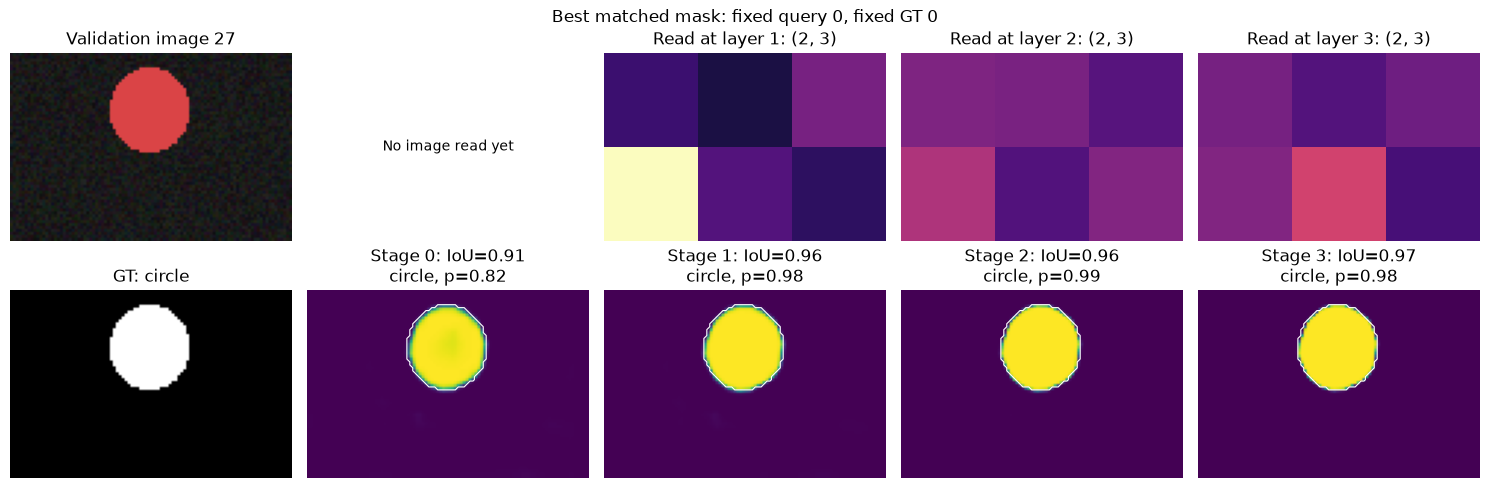

worst {'image': 10, 'query': 6, 'object': 0, 'iou': 0.0, 'correct_class': False}


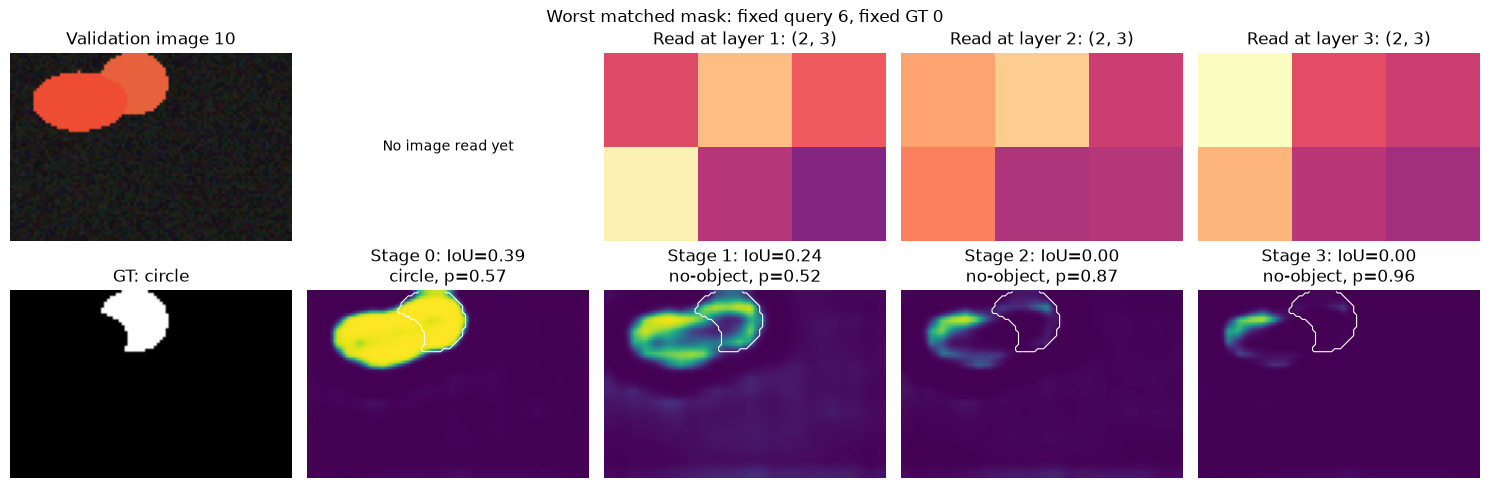

In [40]:
query_examples = select_query_examples(query_demo, comparison_val)
query_trajectories = {}
for name, selection in query_examples.items():
    print(name, selection)
    query_trajectories[name] = show_query_evolution(query_demo, comparison_val, selection, name)
(ARTIFACTS / "query_trajectories.json").write_text(json.dumps({"examples": query_examples, "stages": query_trajectories}, indent=2));

В сохранённом прогоне хорошая маска имеет IoU **0.91 → 0.96 → 0.96 → 0.97**. Уже начальный фиксированный фильтр хорошо выделяет объект по pixel features. Во втором примере **0.39 → 0.24 → 0 → 0**: кандидат теряет объект и становится `no-object`. Это ошибка выбранного кандидата относительно закреплённого GT, а не гарантия поведения остальных queries.

### Нужен ли фильтр именно с этого изображения?

У обученной модели меняем только последний шаг построения масок:

$$e_i(I)^\top F(I,x,y)\quad\longrightarrow\quad e_i(J)^\top F(I,x,y).$$

В каждом batch циклически сдвигаем embeddings между изображениями. Номер query сохраняется, донор всегда другой. Pixel features и классификационные предсказания остаются от исходного изображения. Нового обучения нет.

Сравниваем метрики на всех 32 validation-изображениях одного checkpoint. Это проверка зависимости предсказаний обученной модели от её динамических фильтров. Она не доказывает превосходства над отдельно обученным фиксированным фильтром. Если качество почти не меняется, значит в этом опыте такая зависимость используется слабо.

native {'semantic_miou': 0.7307, 'instance_precision_50': 0.5135, 'instance_recall_50': 0.717}
other_image {'semantic_miou': 0.7217, 'instance_precision_50': 0.5068, 'instance_recall_50': 0.6981}


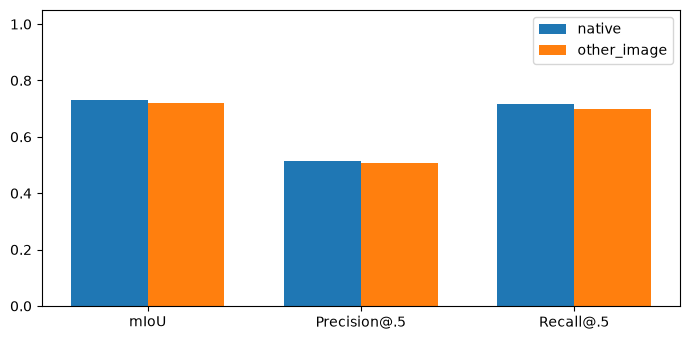

In [41]:
class SwappedMaskEmbeddings(nn.Module):
    def __init__(self, candidate):
        super().__init__()
        self.candidate = candidate

    def forward(self, images):
        if len(images) < 2:
            raise ValueError("Embedding swap needs at least two images per batch")
        output = self.candidate(images)
        pixels = self.candidate.pixels(images)["mask_features"]
        reconstructed = torch.einsum("bnd,bdhw->bnhw", output["mask_embeddings"], pixels)
        torch.testing.assert_close(reconstructed, output["pred_masks"])
        masks = torch.einsum("bnd,bdhw->bnhw", output["mask_embeddings"].roll(1, 0), pixels)
        return {**output, "pred_masks": masks}


swapped_demo = SwappedMaskEmbeddings(query_demo).eval()
swap_metrics = {
    "native": evaluate(query_demo, comparison_loader, 2, DEVICE, SCORE_THRESHOLD),
    "other_image": evaluate(swapped_demo, comparison_loader, 2, DEVICE, SCORE_THRESHOLD),
}
metric_keys = ["semantic_miou", "instance_precision_50", "instance_recall_50"]
figure, axis = plt.subplots(figsize=(7, 3.5))
for offset, (name, metrics) in zip((-0.18, 0.18), swap_metrics.items()):
    axis.bar(np.arange(3) + offset, [metrics[key] for key in metric_keys], width=0.36, label=name)
    print(name, {key: round(metrics[key], 4) for key in metric_keys})
axis.set(xticks=np.arange(3), xticklabels=["mIoU", "Precision@.5", "Recall@.5"], ylim=(0, 1.05))
axis.legend()
figure.tight_layout()
figure.savefig(ARTIFACTS / "embedding_swap_metrics.png", dpi=130)
plt.show()
(ARTIFACTS / "embedding_swap.json").write_text(json.dumps(swap_metrics, indent=2));

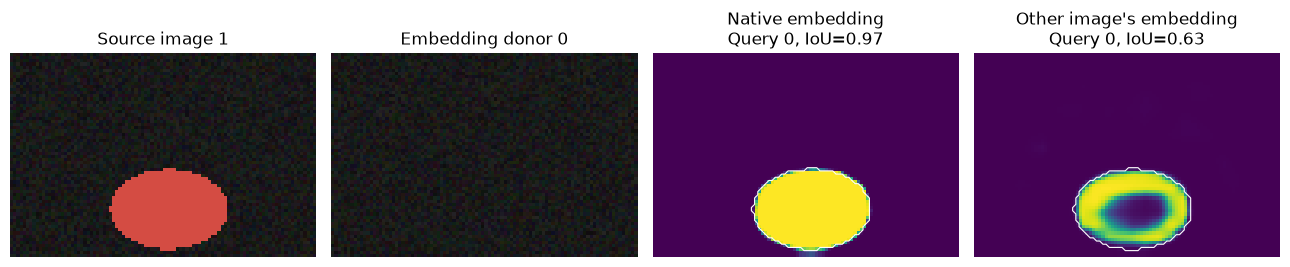

In [42]:
swap_images, swap_targets = next(iter(comparison_loader))
with torch.no_grad():
    native_output = query_demo(swap_images.to(DEVICE))
    swapped_output = swapped_demo(swap_images.to(DEVICE))
torch.testing.assert_close(native_output["pred_logits"], swapped_output["pred_logits"], rtol=0, atol=0)
swap_batch = next(i for i, target in enumerate(swap_targets) if len(target["labels"]))
swap_match = HungarianMatcher()(native_output, targets_to_device(swap_targets, DEVICE))[swap_batch]
swap_query, swap_object = int(swap_match[0][0]), int(swap_match[1][0])
donor_batch = (swap_batch - 1) % len(swap_images)
figure, axes = plt.subplots(1, 4, figsize=(13, 3))
axes[0].imshow(swap_images[swap_batch].permute(1, 2, 0))
axes[0].set_title(f"Source image {swap_batch}")
axes[1].imshow(swap_images[donor_batch].permute(1, 2, 0))
axes[1].set_title(f"Embedding donor {donor_batch}")
for axis, output, name in zip(axes[2:], (native_output, swapped_output), ("Native embedding", "Other image's embedding")):
    logits = F.interpolate(output["pred_masks"], swap_images.shape[-2:], mode="bilinear", align_corners=False)[swap_batch, swap_query].cpu()
    truth = swap_targets[swap_batch]["masks"][swap_object]
    axis.imshow(logits.sigmoid(), cmap="viridis", vmin=0, vmax=1)
    axis.contour(truth, levels=[0.5], colors="white", linewidths=0.8)
    axis.set_title(f"{name}\nQuery {swap_query}, IoU={mask_iou(logits > 0, truth):.2f}")
for axis in axes:
    axis.axis("off")
figure.tight_layout()
figure.savefig(ARTIFACTS / "embedding_swap_masks.png", dpi=130)
plt.show()

В сохранённом прогоне подмена embeddings меняет validation mIoU **0.731 → 0.722**, precision **0.514 → 0.507**, recall **0.717 → 0.698**. Среднее изменение качества небольшое. При этом на показанном объекте IoU меняется с **0.97 до 0.63**: локальное изменение маски может быть заметнее, чем изменение общей метрики. Donor в этом примере — пустое изображение; пример выбран по первому непустому target, а не по величине ухудшения.

### Фиксированные и динамические фильтры с одинаковой классификацией

`conv ↔ global_pool`: у обеих моделей класс читается через mask pooling и LayerNorm + Linear. Начальные веса этого классификатора и pixel decoder совпадают. Число кандидатов, matching, loss, данные и бюджет обучения одинаковы; auxiliary loss выключен.

Меняется построение масок: фиксированная свёртка или embeddings после query decoder. Число параметров и вычисления различаются. Это сравнение двух способов построения масок при общем способе классификации, а не изолированное измерение одной операции attention.

conv           seed=42: mIoU=0.902, precision=0.613, recall=0.717


conv           seed=43: mIoU=0.894, precision=0.756, recall=0.642


conv           seed=44: mIoU=0.878, precision=0.684, recall=0.736


global_pool    seed=42: mIoU=0.914, precision=0.424, recall=0.736


global_pool    seed=43: mIoU=0.928, precision=0.636, recall=0.660


global_pool    seed=44: mIoU=0.933, precision=0.350, recall=0.811


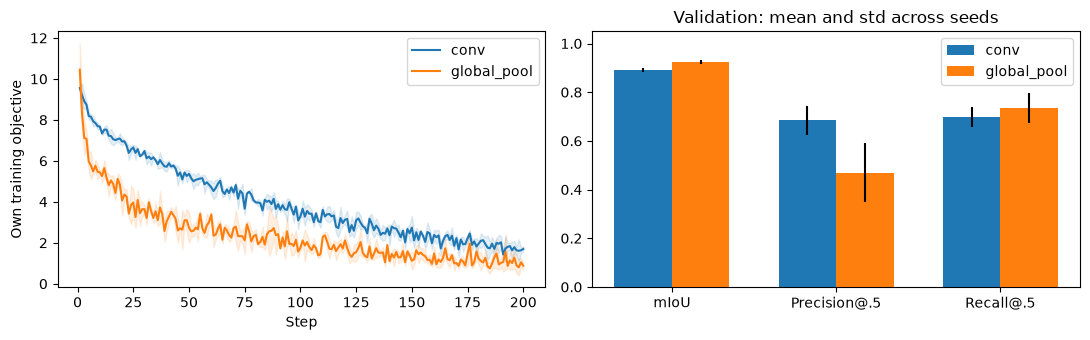

In [43]:
compare_variants("conv", "global_pool")

В сохранённом прогоне mIoU меняется **0.892 → 0.925**, recall **0.698 → 0.736**, а precision падает **0.684 → 0.470**. Динамические фильтры лучше покрывают классы и находят немного больше объектов, но дают больше ложных instance-предсказаний. Смотрим все три метрики.

### Два объекта одного класса: далеко и рядом

Дополнительно проверим те же checkpoint на парах кругов. Для каждого seed данных сохраняем фон, размеры и цвет, меняем расстояние между центрами. Во втором варианте объекты частично перекрываются; target содержит видимые части. Объекты одного класса и цвета: нужно разделить экземпляры.

Эти сцены не участвовали в обучении и отличаются от основного validation. Они проверяют перенос на заданные условия. Изменение расстояния также меняет площадь видимой части, поэтому это не чистое измерение только расстояния. Сравним instance precision/recall и mIoU по трём seeds моделей.

На рисунке первая строка — объекты далеко, вторая — с перекрытием.

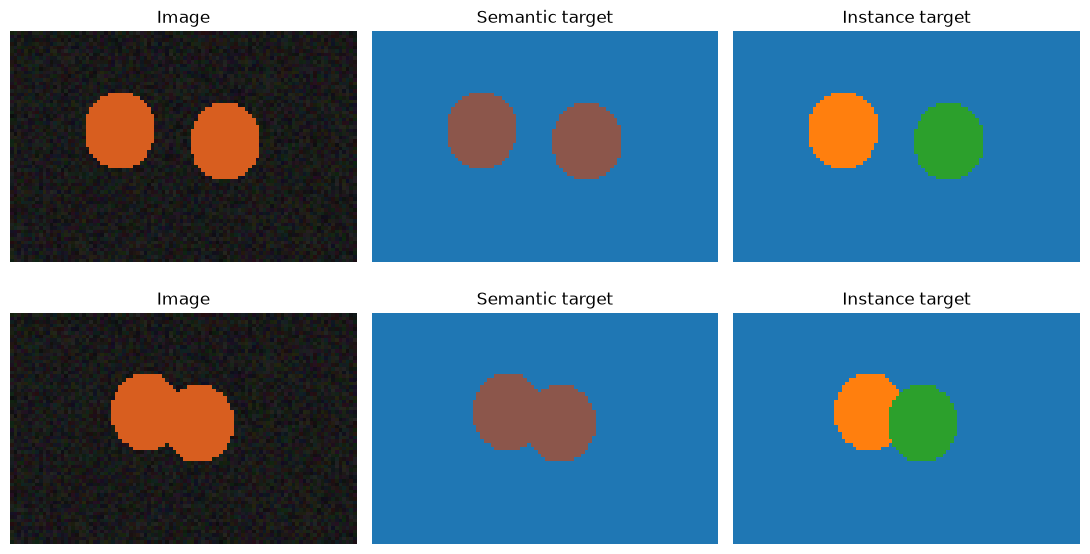

separated  conv        : mIoU=0.915 ± 0.012, precision=0.456 ± 0.177, recall=0.411 ± 0.212
separated  global_pool : mIoU=0.956 ± 0.011, precision=0.228 ± 0.150, recall=0.370 ± 0.364


nearby     conv        : mIoU=0.950 ± 0.003, precision=0.554 ± 0.062, recall=0.333 ± 0.019
nearby     global_pool : mIoU=0.964 ± 0.008, precision=0.342 ± 0.045, recall=0.354 ± 0.145


In [44]:
class PairedCirclesDataset(Dataset):
    def __init__(self, count=32, nearby=False, seed=400123):
        self.count, self.nearby, self.seed = count, nearby, seed

    def __len__(self):
        return self.count

    def __getitem__(self, index):
        rng = np.random.default_rng(self.seed + index)
        height, width = 64, 96
        yy, xx = np.mgrid[:height, :width]
        image = rng.uniform(0.05, 0.15, (height, width, 3)).astype(np.float32)
        rx, ry = rng.uniform(8, 12), rng.uniform(8, 13)
        cx, cy = width / 2 + rng.uniform(-6, 6), height / 2 + rng.uniform(-5, 5)
        distance = (1.5 if self.nearby else 3.0) * rx
        color = np.array([0.85, 0.3, 0.2]) + rng.uniform(-0.08, 0.08, 3)
        instances = np.zeros((height, width), dtype=np.int64)
        for obj, direction in enumerate((-1, 1), 1):
            x, y = cx + direction * distance / 2, cy + direction * ry * 0.15
            mask = ((xx - x) / rx) ** 2 + ((yy - y) / ry) ** 2 <= 1
            image[mask] = color
            instances[mask] = obj
        masks = torch.from_numpy(np.stack([instances == obj for obj in (1, 2)])).float()
        return torch.from_numpy(image.transpose(2, 0, 1)), {"labels": torch.zeros(2, dtype=torch.long), "masks": masks}


pair_data = {"separated": PairedCirclesDataset(), "nearby": PairedCirclesDataset(nearby=True)}
pair_images, pair_targets = collate_instances([data[0] for data in pair_data.values()])
show_batch(pair_images, pair_targets, max_images=2)
plt.show()
pair_results = []
for condition, data in pair_data.items():
    loader = DataLoader(data, batch_size=BATCH_SIZE, collate_fn=collate_instances)
    for variant in ("conv", "global_pool"):
        values = []
        for seed in SEEDS:
            metrics = evaluate(ablation_models[(variant, seed)], loader, 2, DEVICE, SCORE_THRESHOLD)
            pair_results.append({"condition": condition, "variant": variant, "seed": seed, **metrics})
            values.append([metrics[key] for key in metric_keys])
        values = np.array(values)
        summary = ", ".join(f"{name}={mean:.3f} ± {std:.3f}" for name, mean, std in
                            zip(["mIoU", "precision", "recall"], values.mean(0), values.std(0)))
        print(f"{condition:10s} {variant:12s}: {summary}")
(ARTIFACTS / "paired_circles.json").write_text(json.dumps(pair_results, indent=2));

У обеих моделей на этих парах высокий semantic mIoU сочетается с низким instance recall. Можно хорошо закрасить объединение двух кругов и плохо разделить их. В сохранённом прогоне у global_pool ниже precision в обоих условиях; уверенного выигрыша в разделении близких объектов здесь нет.

### Что изменилось в архитектуре

Queries хранят состояния кандидатов. Cross-attention обновляет их по изображению, self-attention позволяет учитывать другие кандидаты, а mask head превращает состояния в фильтры масок. Несколько слоёв повторяют обновление. One-to-one matching задаёт соответствие с GT при обучении; дубликаты на inference всё ещё возможны.

Траектории показывают поведение конкретных кандидатов. Подмена embeddings проверяет зависимость обученной модели от текущего изображения. Парные обучения проверяют качество при заданных данных и бюджете. Выигрыш queries из их определения не следует.

## 4. Обучение промежуточных выходов

При loss только на последнем выходе ранние queries обучаются через все последующие слои. Промежуточные losses добавляют более короткие пути градиента и обучают маски, которые позже станут областями masked attention.

На одном forward обученной модели сравним градиенты от последнего loss и среднего loss по всем стадиям. Усреднение убирает простое увеличение числа слагаемых, но не делает нормы градиентов одинаковыми. Каждый выход использует свой matching.

### От каких выходов приходит градиент

Верхняя схема: loss только на последнем выходе. Нижняя: loss у начального состояния и после каждого слоя. Каждый loss использует свой matching; схема показывает зависимости, а не величину градиентов.

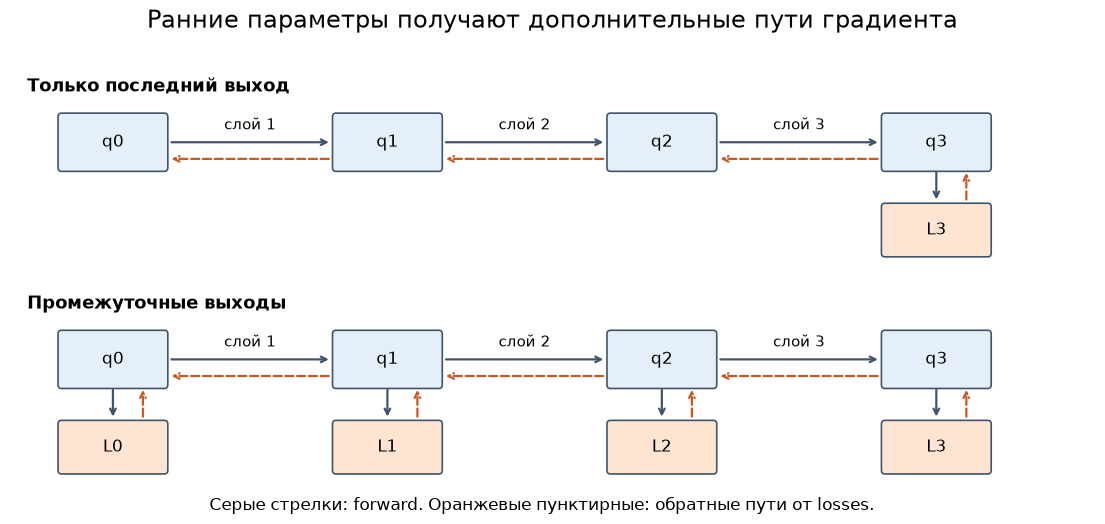

In [45]:
def show_auxiliary_paths():
    figure, axis = diagram_canvas("Ранние параметры получают дополнительные пути градиента", (14, 6))
    xs = [1.0, 4.2, 7.4, 10.6]
    for y, caption, active in [(4.0, "Только последний выход", [3]), (1.65, "Промежуточные выходы", [0, 1, 2, 3])]:
        axis.text(0, y + .55, caption, fontsize=13, weight="bold")
        for index, x in enumerate(xs):
            diagram_box(axis, (x, y), f"q{index}", width=1.2, height=.55)
            if index < 3:
                diagram_arrow(axis, (x + .65, y), (xs[index + 1] - .65, y))
                axis.text((x + xs[index + 1]) / 2, y + .14, f"слой {index + 1}", ha="center", fontsize=11)
            if index in active:
                diagram_box(axis, (x, y - .95), f"L{index}", width=1.2, height=.5, color="#ffe5d1")
                diagram_arrow(axis, (x, y - .3), (x, y - .65))
                diagram_arrow(axis, (x + .35, y - .65), (x + .35, y - .3), color="#c95823", style="--")
        for index in range(3, 0, -1):
            diagram_arrow(axis, (xs[index] - .65, y - .18), (xs[index - 1] + .65, y - .18), color="#c95823", style="--")
    axis.text(6, .02, "Серые стрелки: forward. Оранжевые пунктирные: обратные пути от losses.", ha="center", fontsize=12)
    finish_visual(figure, "04a_auxiliary_paths")


show_auxiliary_paths()

In [46]:
previous_auxiliary = query_demo.auxiliary_loss
try:
    query_demo.auxiliary_loss = True
    aux_output = query_demo(images)
finally:
    query_demo.auxiliary_loss = previous_auxiliary
stage_outputs = [*aux_output["aux_outputs"], aux_output]
stage_losses = [criterion.weighted(criterion.single_loss(stage, targets)) for stage in stage_outputs]
watched = [query_demo.query_features.weight,
           query_demo.decoder[0].cross_attention.in_proj_weight,
           query_demo.decoder[-1].cross_attention.in_proj_weight]
final_gradients = torch.autograd.grad(stage_losses[-1], watched, retain_graph=True)
mean_gradients = torch.autograd.grad(torch.stack(stage_losses).mean(), watched)
print("parameter | final-only norm | mean-stage norm | cosine")
for name, last, mean in zip(["queries", "first cross-attention", "last cross-attention"], final_gradients, mean_gradients):
    cosine = F.cosine_similarity(last.flatten(), mean.flatten(), dim=0)
    print(f"{name:22s} | {last.norm().item():.4f} | {mean.norm().item():.4f} | {cosine.item():.4f}")

parameter | final-only norm | mean-stage norm | cosine
queries                | 0.5076 | 0.3784 | 0.6992
first cross-attention  | 2.5360 | 1.5288 | 0.8161
last cross-attention   | 1.6481 | 0.4120 | 1.0000


### Меняются величина и направление градиента

Измерения на том же forward обученной модели: последний loss против среднего по четырём стадиям. Cosine 1 означает совпадающее направление. У последнего слоя усреднение только уменьшает градиент в четыре раза.

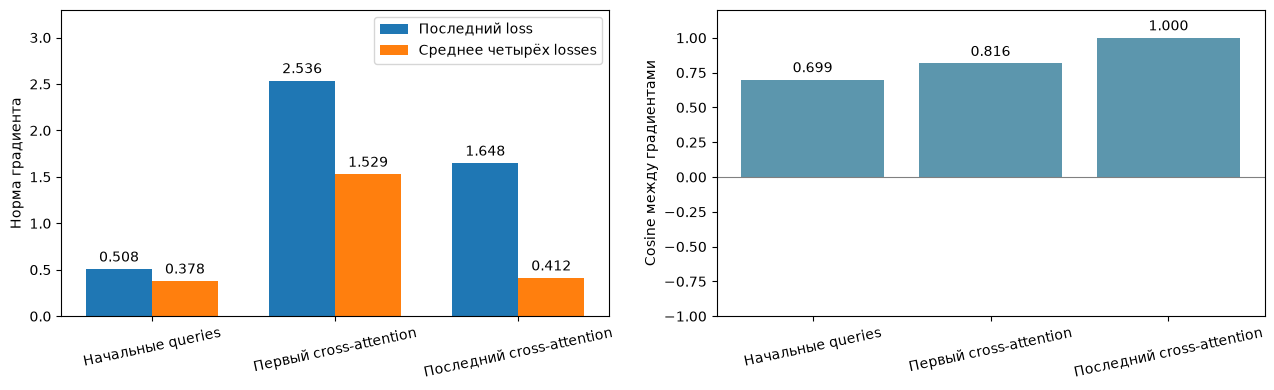

In [47]:
def show_auxiliary_gradients():
    labels = ["Начальные queries", "Первый cross-attention", "Последний cross-attention"]
    norms = np.array([[last.norm().item(), mean.norm().item()] for last, mean in zip(final_gradients, mean_gradients)])
    cosines = [F.cosine_similarity(last.flatten(), mean.flatten(), dim=0).item() for last, mean in zip(final_gradients, mean_gradients)]
    figure, axes = plt.subplots(1, 2, figsize=(13, 4))
    for offset, column, label in [(-.18, 0, "Последний loss"), (.18, 1, "Среднее четырёх losses")]:
        bars = axes[0].bar(np.arange(3) + offset, norms[:, column], width=.36, label=label)
        axes[0].bar_label(bars, fmt="%.3f", padding=3, fontsize=10)
    axes[0].set(xticks=np.arange(3), xticklabels=labels, ylabel="Норма градиента", ylim=(0, norms.max() * 1.3))
    axes[0].tick_params(axis="x", labelrotation=12)
    axes[0].legend(fontsize=10)
    bars = axes[1].bar(np.arange(3), cosines, color="#5c96ad")
    axes[1].bar_label(bars, fmt="%.3f", padding=3)
    axes[1].set(xticks=np.arange(3), xticklabels=labels, ylabel="Cosine между градиентами", ylim=(-1, 1.2))
    axes[1].tick_params(axis="x", labelrotation=12)
    axes[1].axhline(0, color="gray", linewidth=.8)
    figure.tight_layout()
    finish_visual(figure, "04b_gradient_measurement")


show_auxiliary_gradients()

У последнего слоя направление градиента сохраняется: промежуточные выходы не зависят от его параметров, и усреднение только уменьшает его вклад. У queries и ранних слоёв добавляются другие направления.

В обучении ниже используется исходная сумма промежуточных losses. Сравнение `global_no_aux ↔ global` проверяет этот вариант целиком: меняются и пути градиента, и масштаб objective. Локальная проверка выше отдельно показывает изменение направления градиента после усреднения.

global_no_aux  seed=43: mIoU=0.735, precision=0.493, recall=0.642


global_no_aux  seed=44: mIoU=0.702, precision=0.363, recall=0.698


global         seed=42: mIoU=0.788, precision=0.702, recall=0.623


global         seed=43: mIoU=0.650, precision=0.441, recall=0.566


global         seed=44: mIoU=0.763, precision=0.313, recall=0.679


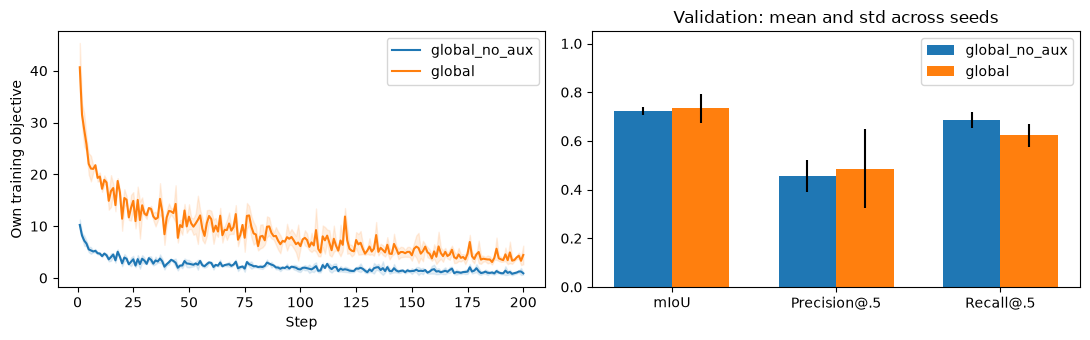

In [48]:
compare_variants("global_no_aux", "global")

## 5. Masked attention

Предыдущая маска ограничивает область cross-attention:

$$\operatorname{softmax}\left(\frac{QK^\top}{\sqrt d}+A(m^{l-1})\right)V,$$

где $A=0$ внутри разрешённой области и $A=-\infty$ снаружи. В PyTorch `True` в `attn_mask` означает запрет.

Маски предсказываются до первого слоя и после каждого следующего. Logits интерполируются до размера memory, порогуются и отсоединяются от графа.

Что произойдёт с softmax, если query запретит себе все позиции?

Глобальное attention должно само научиться выделять полезную область среди всех spatial tokens. Предыдущая маска даёт пространственное ограничение: проверяем гипотезу, что оно помогает собирать признаки объекта. Ошибочная ранняя маска может исключить нужные признаки — поэтому выигрыш проверяем обучением, а не предполагаем заранее.

In [49]:
def attention_mask(mask_logits, size, heads):
    blocked = F.interpolate(mask_logits.detach(), size=size, mode="bilinear", align_corners=False)
    blocked = blocked.flatten(2) < 0
    empty = blocked.all(dim=-1)
    blocked = blocked & ~empty.unsqueeze(-1)
    per_head = blocked.repeat_interleave(heads, dim=0)
    return per_head, ~blocked, empty

### Что именно меняет маска в attention

Ручной пример для одного query и шести позиций memory. Запрещённые позиции получают −∞ до softmax; веса разрешённых позиций нормируются заново.

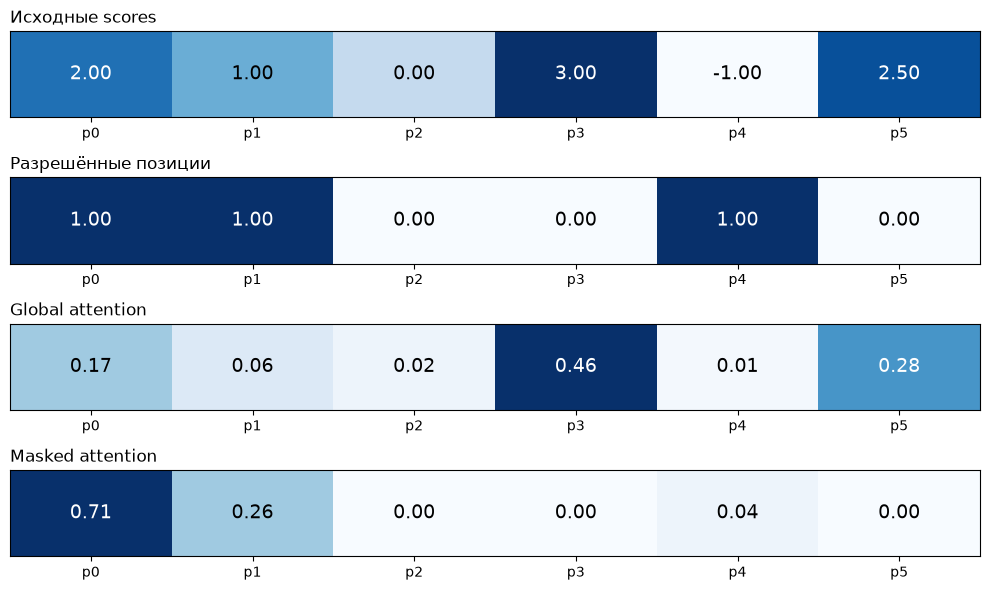

In [50]:
def show_masked_softmax():
    scores = torch.tensor([2., 1., 0., 3., -1., 2.5])
    allowed = torch.tensor([True, True, False, False, True, False])
    masked_scores = scores.masked_fill(~allowed, -torch.inf)
    values = [scores, allowed.float(), scores.softmax(-1), masked_scores.softmax(-1)]
    titles = ["Исходные scores", "Разрешённые позиции", "Global attention", "Masked attention"]
    figure, axes = plt.subplots(4, 1, figsize=(10, 6))
    for axis, value, title in zip(axes, values, titles):
        axis.imshow(value[None], cmap="Blues", aspect="auto", vmin=min(0, float(value.min())), vmax=float(value.max()))
        for position, number in enumerate(value):
            axis.text(position, 0, f"{number:.2f}", ha="center", va="center", fontsize=14,
                      color="white" if number > .6 * value.max() else "black")
        axis.set(yticks=[], xticks=range(6), xticklabels=[f"p{i}" for i in range(6)])
        axis.set_title(title, loc="left", fontsize=12)
    figure.tight_layout()
    finish_visual(figure, "05a_masked_softmax")


show_masked_softmax()

### Мини-абляция: полностью запрещённая строка

Сначала считаем обычный softmax от одних −∞. Затем применяем восстановление строки из `attention_mask`. Разрешение всей memory даёт query возможность заново найти объект после пустой маски.

In [51]:
all_forbidden_scores = torch.full((1, 16), -torch.inf, device=DEVICE)
print("Finite softmax without fallback:", bool(torch.isfinite(all_forbidden_scores.softmax(-1)).all()))
assert torch.isnan(all_forbidden_scores.softmax(-1)).all()

Finite softmax without fallback: False


In [52]:
all_negative = torch.full((1, 2, 8, 8), -10.0, device=DEVICE, requires_grad=True)
blocked, allowed, fallback = attention_mask(all_negative, size=(4, 4), heads=4)
assert fallback.all() and allowed.all() and not blocked.any()
print("Empty rows reopened:", fallback.tolist(), "mask requires_grad:", blocked.requires_grad)

Empty rows reopened: [[True, True]] mask requires_grad: False


### Пустая маска и восстановление чтения

В примере исходные scores равны нулю. Если запретить все позиции, softmax даёт NaN. После fallback снова доступны все позиции; в этом частном примере их веса равны.

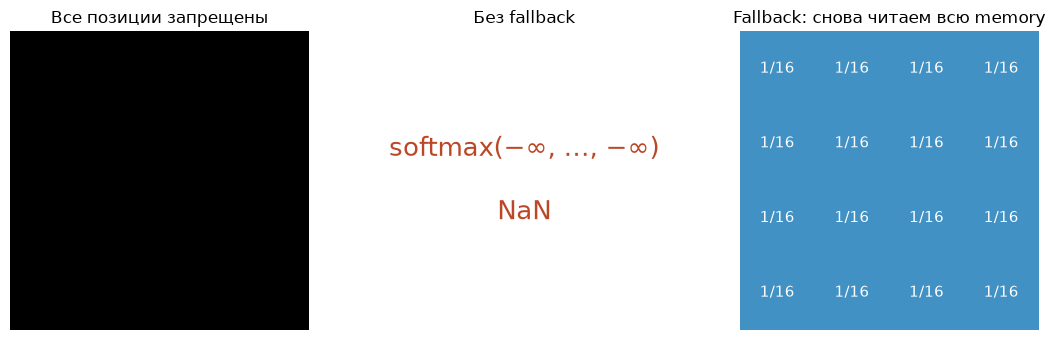

In [53]:
def show_empty_attention():
    logits = torch.full((1, 1, 4, 4), -10.)
    blocked, allowed, empty = attention_mask(logits, (4, 4), 1)
    assert empty.all() and allowed.all() and not blocked.any()
    before = torch.zeros(4, 4)
    after = torch.zeros(16).masked_fill(blocked[0, 0], -torch.inf).softmax(-1).reshape(4, 4)
    figure, axes = plt.subplots(1, 3, figsize=(11, 3.5))
    axes[0].imshow(before, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Все позиции запрещены")
    axes[1].text(.5, .5, "softmax(−∞, …, −∞)\n\nNaN", ha="center", va="center", fontsize=19, color="#bc4727")
    axes[1].set_title("Без fallback")
    axes[2].imshow(after, cmap="Blues", vmin=0, vmax=.1)
    axes[2].set_title("Fallback: снова читаем всю memory")
    for y in range(4):
        for x in range(4):
            axes[2].text(x, y, "1/16", ha="center", va="center", fontsize=11, color="white")
    for axis in axes:
        axis.axis("off")
    figure.tight_layout()
    finish_visual(figure, "05b_empty_fallback")


show_empty_attention()

### Парное обучение: global ↔ masked

Веса всех параметров на старте, масштабы memory и auxiliary loss совпадают. Меняется только булев запрет в cross-attention. Смотрим, изменились ли скорость снижения objective и validation-метрики за одинаковое число шагов.

masked         seed=42: mIoU=0.832, precision=0.571, recall=0.679


masked         seed=43: mIoU=0.721, precision=0.466, recall=0.642


masked         seed=44: mIoU=0.558, precision=0.397, recall=0.434


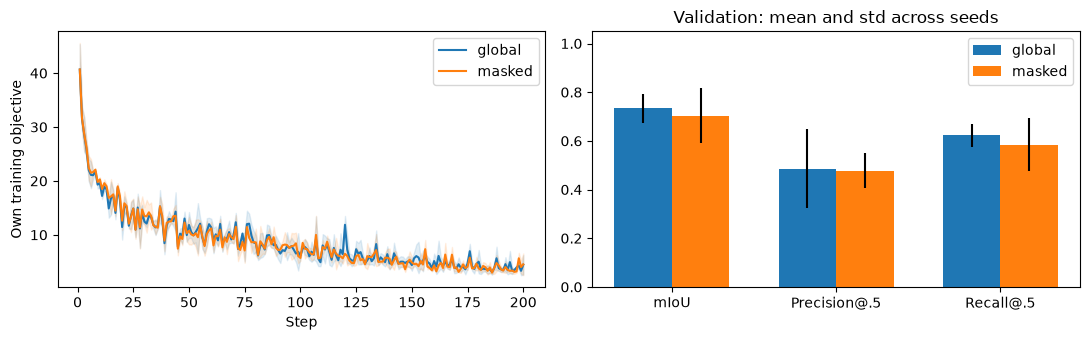

In [54]:
compare_variants("global", "masked")

### Обучение на восьми изображениях

Обучаем модель с masked attention и тремя масштабами. Сравниваем метрики на тренировочных и новых изображениях.

In [55]:
def show_history(history):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot([row["step"] for row in history], [row["loss"] for row in history])
    ax.set(xlabel="Step", ylabel="Training objective", title="Overfit check on a small dataset")
    ax.grid(alpha=0.2)
    fig.tight_layout()
    return fig

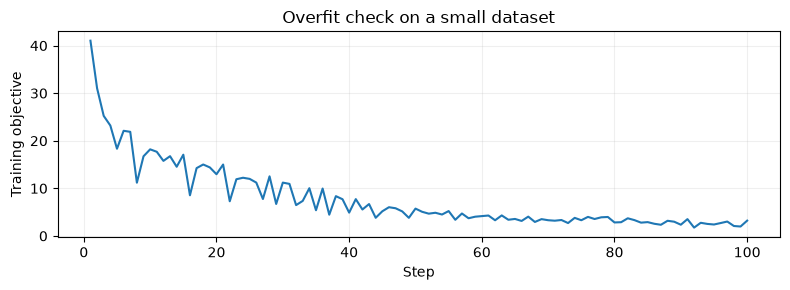

In [56]:
seed_everything(42)
train_set = ShapesDataset(count=8, seed=42)
train_loader = DataLoader(train_set, batch_size=4, shuffle=True, collate_fn=collate_instances,
                          generator=torch.Generator().manual_seed(42))
val_loader = DataLoader(ShapesDataset(count=16, seed=100042), batch_size=4, collate_fn=collate_instances)
model = QuerySegmenter(num_classes=2, dim=32, layers=3, masked_attention=True, multiscale=True).to(DEVICE)

history = train_steps(model, train_loader, SetCriterion(num_classes=2),
                      steps=TRAIN_STEPS, learning_rate=0.001, device=DEVICE)
torch.save({"state_dict": model.state_dict(), "training_steps": TRAIN_STEPS}, ARTIFACTS / "overfit_shapes.pt")
(ARTIFACTS / "history.json").write_text(json.dumps(history, indent=2))
show_history(history)
plt.show()

In [57]:
train_metrics = evaluate(model, DataLoader(train_set, batch_size=4, collate_fn=collate_instances), 2, DEVICE)
val_metrics = evaluate(model, val_loader, 2, DEVICE)
print("Train:", train_metrics)
print("Validation:", val_metrics)

Train: {'semantic_miou': 0.9786613583564758, 'per_class_iou': [0.9939059019088745, 0.9799270033836365, 0.9621514081954956], 'instance_precision_50': 0.9230769230769231, 'instance_recall_50': 1.0, 'instance_tp': 12, 'instance_fp': 1, 'instance_fn': 0}
Validation: {'semantic_miou': 0.38005533814430237, 'per_class_iou': [0.9232224822044373, 0.0, 0.21694354712963104], 'instance_precision_50': 0.10526315789473684, 'instance_recall_50': 0.08333333333333333, 'instance_tp': 2, 'instance_fp': 17, 'instance_fn': 22}


In [58]:
def show_predictions(images, targets, predictions):
    count = min(len(images), 4)
    fig, axes = plt.subplots(count, 3, figsize=(11, 3 * count), squeeze=False)
    for row in range(count):
        axes[row, 0].imshow(images[row].detach().cpu().permute(1, 2, 0).clamp(0, 1))
        for column, masks in [(1, targets[row]["masks"]), (2, predictions[row]["masks"])]:
            canvas = torch.zeros(images.shape[-2:])
            for index, mask in enumerate(masks):
                canvas[mask.cpu() > 0.5] = index + 1
            axes[row, column].imshow(canvas, vmin=0, vmax=8, cmap="tab10")
        for ax, title in zip(axes[row], ["Image", "Ground truth", "Predicted instances"]):
            ax.set_title(title)
            ax.axis("off")
    fig.tight_layout()
    return fig


def show_query_trace(output, query, batch=0, head=0):
    traces, stages = output["trace"], output["stages"]
    fig, axes = plt.subplots(4, len(traces), figsize=(4 * len(traces), 10), squeeze=False)
    for column, trace in enumerate(traces):
        size = trace["size"]
        before = stages[column]["pred_masks"][batch, query].sigmoid().cpu()
        allowed = trace["allowed"][batch, query].reshape(size).cpu()
        attention = trace["cross_attention"][batch, head, query].reshape(size).cpu()
        after = stages[column + 1]["pred_masks"][batch, query].sigmoid().cpu()
        for row, data in enumerate([before, allowed, attention, after]):
            axes[row, column].imshow(data, cmap="viridis", vmin=0, vmax=1 if row != 2 else None)
            axes[row, column].axis("off")
        axes[0, column].set_title(f"Layer {column + 1}, memory {tuple(size)}")
        confidence = stages[column + 1]["pred_logits"][batch, query].softmax(-1)
        label = int(confidence.argmax())
        axes[3, column].set_title(f"class={label}, score={float(confidence.max()):.2f}")
    for row, name in enumerate(["Mask before", "Allowed attention", "Actual attention", "Mask after"]):
        axes[row, 0].text(-0.08, 0.5, name, transform=axes[row, 0].transAxes, rotation=90, va="center")
    fig.suptitle(f"Query {query}, batch {batch}, attention head {head}")
    fig.tight_layout()
    return fig

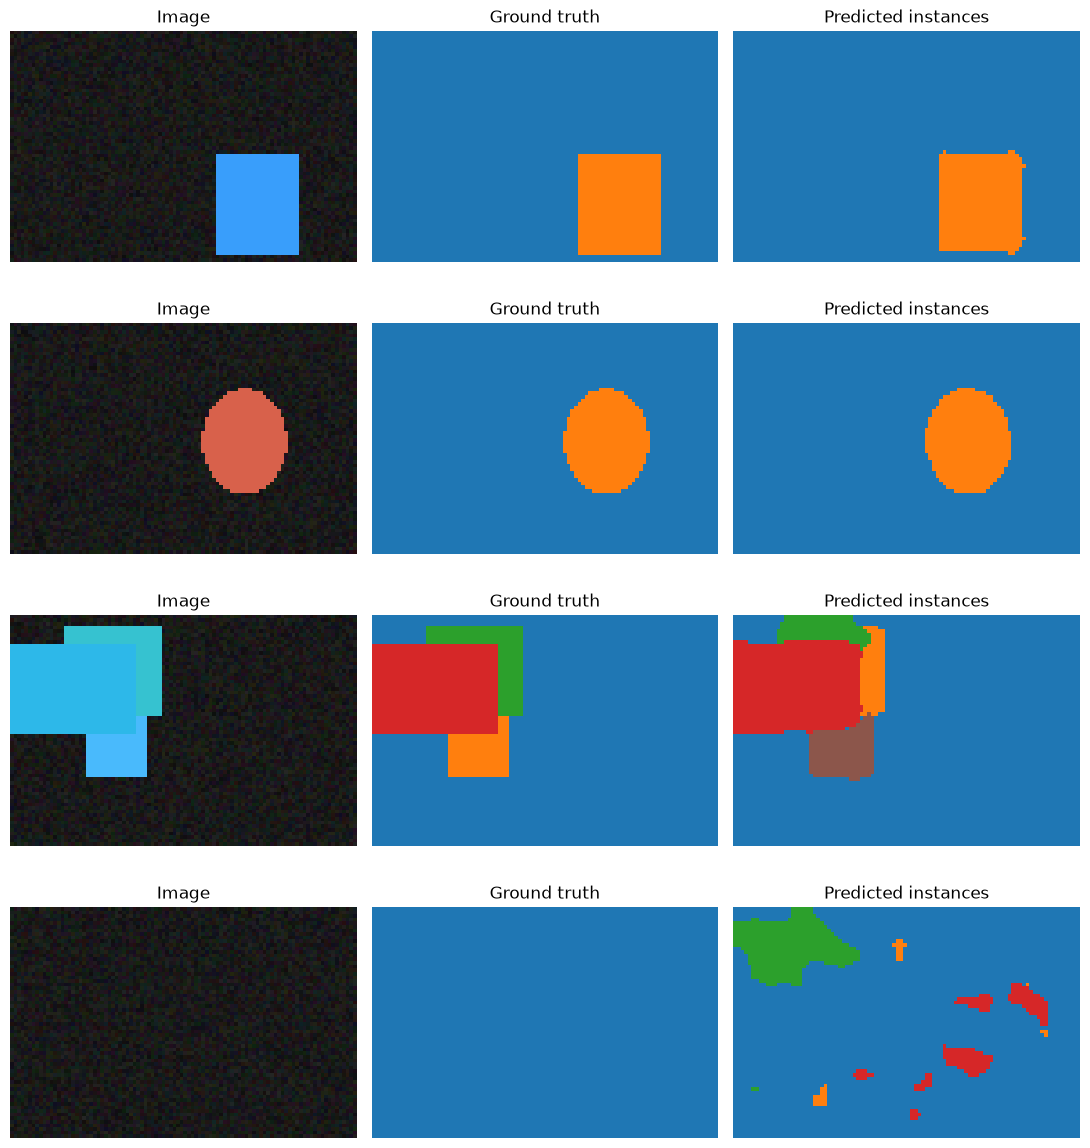

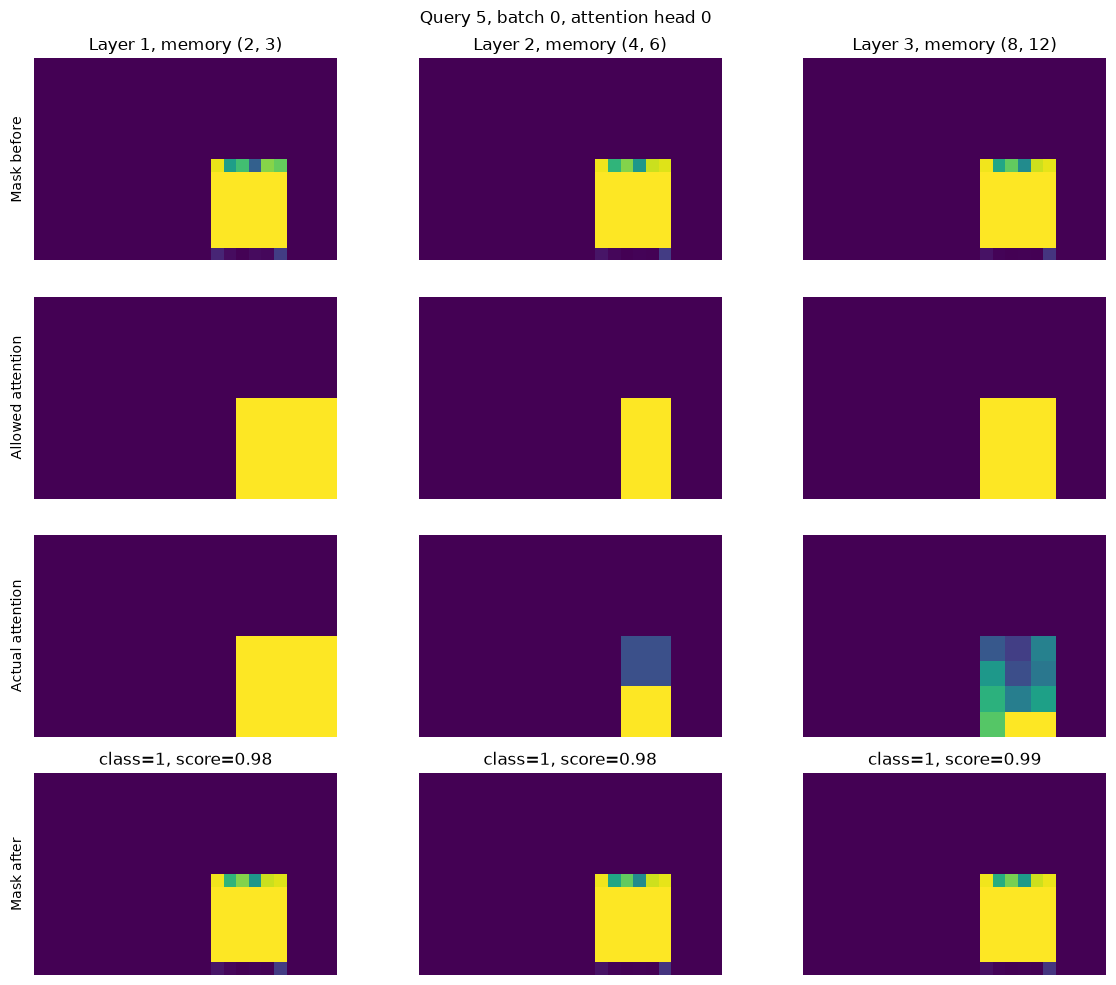

In [59]:
model.eval()
with torch.no_grad():
    trained_output = model(images, return_trace=True)
predictions = predict_instances(trained_output, images.shape[-2:])
show_predictions(images, targets, predictions)
plt.show()

matched = SetCriterion(num_classes=2).matcher(trained_output, targets)
query = int(matched[0][0][0])
figure = show_query_trace(trained_output, query=query, batch=0, head=0)
figure.savefig(ARTIFACTS / "query_trace.png", dpi=130)
plt.show()

Строки: маска до слоя, разрешённая область attention, веса одной головы cross-attention, маска после слоя.

Attention вычисляется на сетке memory. Проверим сумму весов и значения в запрещённых позициях.

In [60]:
for layer, trace in enumerate(trained_output["trace"]):
    weights = trace["cross_attention"]
    torch.testing.assert_close(weights.sum(-1), torch.ones_like(weights[..., 0]))
    forbidden = ~trace["allowed"].unsqueeze(1).expand_as(weights)
    assert torch.count_nonzero(weights[forbidden]) == 0
    print(f"Layer {layer}: memory={tuple(trace['size'])}, empty fallbacks={int(trace['empty_fallback'].sum())}")

Layer 0: memory=(2, 3), empty fallbacks=28
Layer 1: memory=(4, 6), empty fallbacks=19
Layer 2: memory=(8, 12), empty fallbacks=12


### Отключение маски на inference

Сравним предсказания с теми же весами при включённом и выключенном ограничении attention. Парное обучение global/masked показано выше.

На одном обученном checkpoint дополнительно сравним validation-метрики при включённой и выключенной маске. Это чувствительность inference к изменению режима. Обучение без маски уже проверено отдельной парой выше.

In [61]:
original_mode = model.masked_attention
try:
    inference_metrics = {}
    for use_mask in (True, False):
        model.masked_attention = use_mask
        inference_metrics[use_mask] = evaluate(model, val_loader, 2, DEVICE)
    model.masked_attention = False
    with torch.no_grad():
        unmasked_output = model(images)
finally:
    model.masked_attention = original_mode
difference = (trained_output["pred_masks"].sigmoid() - unmasked_output["pred_masks"].sigmoid()).abs().mean()
print("Mean mask probability change:", float(difference))
for use_mask, metrics in inference_metrics.items():
    print(f"masked={use_mask}: mIoU={metrics['semantic_miou']:.3f}, "
          f"precision={metrics['instance_precision_50']:.3f}, recall={metrics['instance_recall_50']:.3f}")

Mean mask probability change: 0.011530746705830097
masked=True: mIoU=0.380, precision=0.105, recall=0.083
masked=False: mIoU=0.380, precision=0.053, recall=0.042


### Отключение ограничения у обученной модели

Один checkpoint, один query и одно изображение. Сравниваем маски и абсолютную разницу вероятностей. Ниже — validation-метрики с ограничением и без него; это вмешательство на inference, отдельное от сравнения двух обучений.

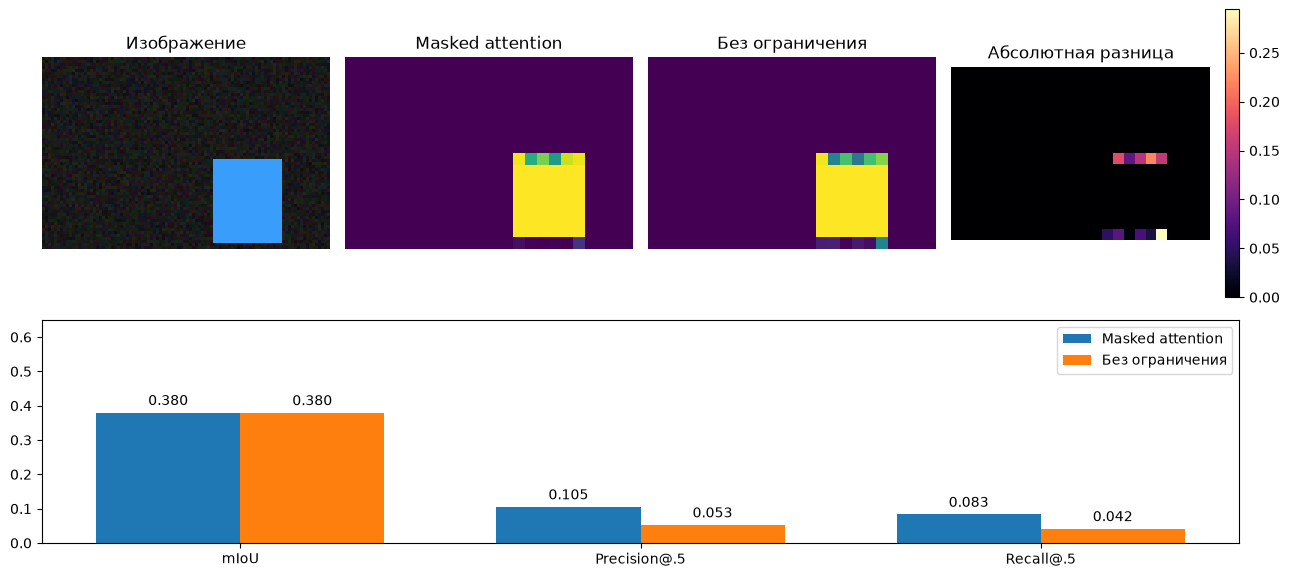

In [62]:
def show_attention_intervention():
    before = trained_output["pred_masks"][0, query].sigmoid().cpu()
    after = unmasked_output["pred_masks"][0, query].sigmoid().cpu()
    delta = (before - after).abs()
    figure = plt.figure(figsize=(13, 6))
    grid = figure.add_gridspec(2, 4, height_ratios=[1.4, 1])
    panels = [(images[0].cpu().permute(1, 2, 0), "Изображение"), (before, "Masked attention"),
              (after, "Без ограничения"), (delta, "Абсолютная разница")]
    for index, (value, title) in enumerate(panels):
        axis = figure.add_subplot(grid[0, index])
        if index == 0:
            axis.imshow(value)
        else:
            artist = axis.imshow(value, cmap="magma" if index == 3 else "viridis", vmin=0,
                                 vmax=max(float(delta.max()), 1e-6) if index == 3 else 1)
            if index == 3:
                figure.colorbar(artist, ax=axis, fraction=.05)
        axis.set_title(title, fontsize=12)
        axis.axis("off")
    axis = figure.add_subplot(grid[1, :])
    keys = ["semantic_miou", "instance_precision_50", "instance_recall_50"]
    for offset, use_mask, name in [(-.18, True, "Masked attention"), (.18, False, "Без ограничения")]:
        bars = axis.bar(np.arange(3) + offset, [inference_metrics[use_mask][key] for key in keys], width=.36, label=name)
        axis.bar_label(bars, fmt="%.3f", padding=3)
    axis.set(xticks=range(3), xticklabels=["mIoU", "Precision@.5", "Recall@.5"], ylim=(0, .65))
    axis.legend()
    figure.tight_layout()
    finish_visual(figure, "05c_mask_intervention")


show_attention_intervention()

## 6. Масштабы и память

U-Net decoder создаёт memory на strides 32, 16 и 8. Слои query decoder циклически выбирают масштабы. Маски строятся по общей карте признаков на stride 4.

Матрица cross-attention имеет размер $N\times H_lW_l$ на голову. Булева маска запрещает связи, но размер плотной матрицы остаётся прежним.

На грубой memory маленький объект представлен немногими позициями. Более подробные масштабы дают queries другой пространственный контекст. У обоих вариантов карта выходных масок остаётся на stride 4: меняется разрешение того, что читает query, а не разрешение mask logits.

In [63]:
with torch.no_grad():
    features = model.pixels(images)
for level, memory in enumerate(features["memories"]):
    tokens = memory.shape[-2] * memory.shape[-1]
    print(f"Level {level}: {tuple(memory.shape)}, Q×HW={model.num_queries * tokens}")
print("Mask feature grid:", tuple(features["mask_features"].shape))
print("Decoder level order:", [trace["level"] for trace in trained_output["trace"]])

Level 0: (4, 32, 2, 3), Q×HW=48
Level 1: (4, 32, 4, 6), Q×HW=192
Level 2: (4, 32, 8, 12), Q×HW=768
Mask feature grid: (4, 32, 16, 24)
Decoder level order: [0, 1, 2]


### Сколько ячеек приходится на маленький объект

Берём самую маленькую GT-маску в демонстрационном batch и усредняем её по ячейкам разных сеток. Цвет показывает долю объекта в ячейке. Это иллюстрация пространственного покрытия по GT, а не карта признаков или предсказание модели.

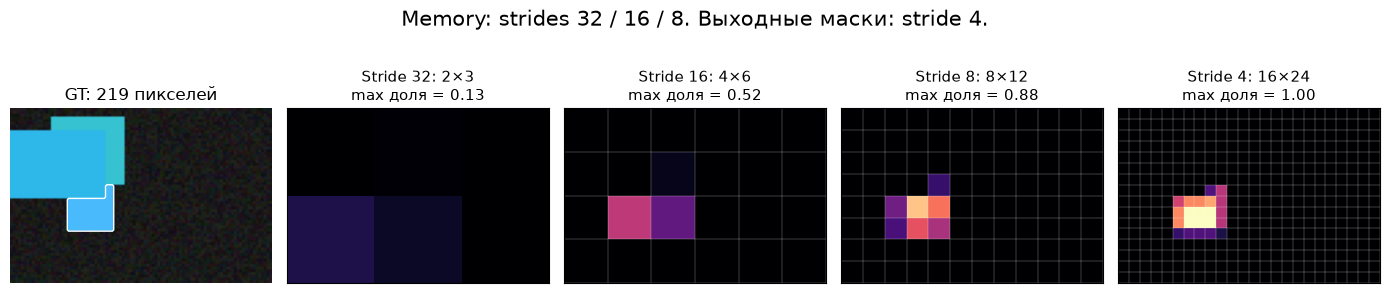

In [64]:
def show_object_resolution():
    choices = [(float(mask.sum()), batch, obj) for batch, target in enumerate(targets) for obj, mask in enumerate(target["masks"])]
    _, batch, obj = min(choices)
    mask = targets[batch]["masks"][obj].cpu()
    sizes = [(mask.shape[0] // stride, mask.shape[1] // stride) for stride in (32, 16, 8, 4)]
    figure, axes = plt.subplots(1, 5, figsize=(14, 3.5))
    axes[0].imshow(images[batch].cpu().permute(1, 2, 0))
    axes[0].contour(mask, levels=[.5], colors="white", linewidths=1)
    axes[0].set_title(f"GT: {int(mask.sum())} пикселей")
    axes[0].axis("off")
    for axis, size, stride in zip(axes[1:], sizes, (32, 16, 8, 4)):
        coverage = F.adaptive_avg_pool2d(mask[None, None], size)[0, 0]
        axis.imshow(coverage, cmap="magma", vmin=0, vmax=1, interpolation="nearest")
        axis.set_title(f"Stride {stride}: {size[0]}×{size[1]}\nmax доля = {coverage.max():.2f}", fontsize=11)
        axis.set_xticks(np.arange(-.5, size[1], 1), minor=True)
        axis.set_yticks(np.arange(-.5, size[0], 1), minor=True)
        axis.grid(which="minor", color="white", linewidth=.35, alpha=.5)
        axis.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
    figure.suptitle("Memory: strides 32 / 16 / 8. Выходные маски: stride 4.", fontsize=15)
    figure.tight_layout()
    finish_visual(figure, "06a_object_resolution")


show_object_resolution()

### Цена более подробной memory

Считаем элементы одной матрицы cross-attention: N×HW на изображение и голову. Булева маска не меняет эти размеры. Это размер матрицы attention, а не полное потребление памяти модели.

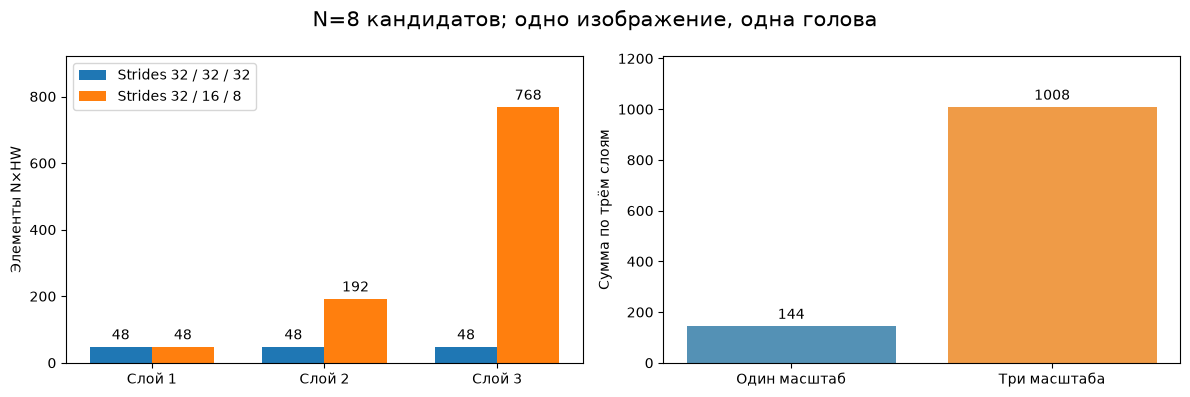

In [65]:
def show_attention_sizes():
    token_counts = [level.shape[-2] * level.shape[-1] for level in features["memories"]]
    coarse = np.repeat(token_counts[0], 3) * model.num_queries
    multi = np.array(token_counts) * model.num_queries
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    for offset, values, label in [(-.18, coarse, "Strides 32 / 32 / 32"), (.18, multi, "Strides 32 / 16 / 8")]:
        bars = axes[0].bar(np.arange(3) + offset, values, width=.36, label=label)
        axes[0].bar_label(bars, padding=3)
    axes[0].set(xticks=range(3), xticklabels=["Слой 1", "Слой 2", "Слой 3"], ylabel="Элементы N×HW", ylim=(0, multi.max() * 1.2))
    axes[0].legend()
    bars = axes[1].bar([0, 1], [coarse.sum(), multi.sum()], color=["#5491b5", "#ef9b47"])
    axes[1].bar_label(bars, padding=3)
    axes[1].set(xticks=[0, 1], xticklabels=["Один масштаб", "Три масштаба"], ylabel="Сумма по трём слоям", ylim=(0, multi.sum() * 1.2))
    figure.suptitle(f"N={model.num_queries} кандидатов; одно изображение, одна голова", fontsize=15)
    figure.tight_layout()
    finish_visual(figure, "06b_attention_size")


show_attention_sizes()

### Парное обучение: один масштаб ↔ три

`masked ↔ multiscale`: сохраняем три слоя decoder, masked attention и auxiliary loss. Сравниваем чтение strides `32, 32, 32` и `32, 16, 8`. Последовательность coarse-to-fine даёт возможность сначала собрать крупный контекст, затем прочитать более подробные признаки. Цена — больше spatial tokens в поздних слоях.

multiscale     seed=42: mIoU=0.825, precision=0.566, recall=0.566


multiscale     seed=43: mIoU=0.730, precision=0.739, recall=0.642


multiscale     seed=44: mIoU=0.626, precision=0.354, recall=0.660


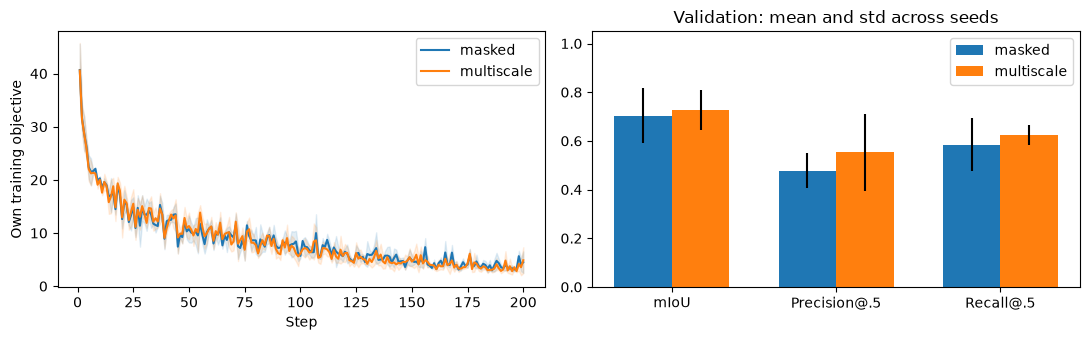

In [66]:
compare_variants("masked", "multiscale")

### Loss по точкам

Плотный loss требует интерполяции масок до разрешения разметки. Вместо всех пикселей можно использовать выбранные точки:

- Для matching — общие случайные координаты для всех пар масок внутри изображения.
- Для loss — отдельные координаты каждой matched-маски: 75% из неуверенных кандидатов и 25% равномерных.

Координаты выбираются без градиента; sampled logits сохраняют градиент. Низкоразмерная сетка масок по-прежнему вычисляется целиком.

Неуверенность выбирает точки с logits около нуля. Уверенно ошибочные точки могут не попасть в такой отбор; случайная часть оставляет им шанс участвовать в loss.

Здесь ограничение — объём промежуточных тензоров для mask loss на полном разрешении. Равномерные точки приближают среднюю ошибку, а выбор неуверенных точек меняет распределение supervision в пользу сложных участков. Это может экономить вычисления и одновременно менять оптимизацию.

In [67]:
def sample_points(masks, coordinates):
    sampled = F.grid_sample(
        masks.unsqueeze(1), coordinates.unsqueeze(2) * 2 - 1,
        mode="bilinear", align_corners=False,
    )
    return sampled[:, 0, :, 0]


@torch.no_grad()
def uncertain_points(logits, count, oversample=3, importance=0.75):
    candidates = torch.rand(logits.shape[0], count * oversample, 2, device=logits.device)
    uncertainty = -sample_points(logits, candidates).abs()
    important_count = int(count * importance)
    indices = uncertainty.topk(important_count, dim=1).indices
    important = candidates.gather(1, indices.unsqueeze(-1).expand(-1, -1, 2))
    random = torch.rand(logits.shape[0], count - important_count, 2, device=logits.device)
    return torch.cat([important, random], dim=1)

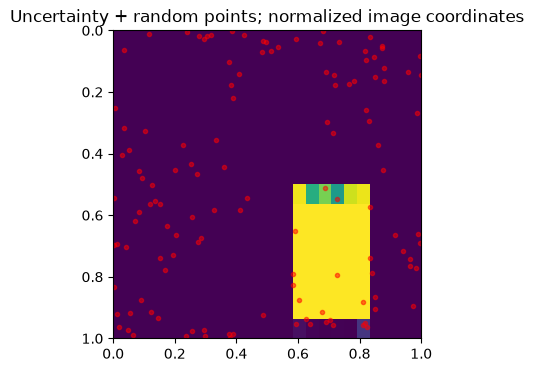

Sampled losses: {'class': 0.1724, 'mask': 0.0691, 'dice': 0.1376, 'auxiliary': 5.1183, 'loss': 6.4966}
Mask head gradient: 7.073521137237549


In [68]:
mask = trained_output["pred_masks"][0, query:query + 1]
coordinates = uncertain_points(mask, count=128)[0].cpu()
figure, ax = plt.subplots(figsize=(6, 4))
ax.imshow(mask[0].sigmoid().cpu(), extent=(0, 1, 1, 0), cmap="viridis", vmin=0, vmax=1)
ax.scatter(coordinates[:, 0], coordinates[:, 1], s=9, c="red", alpha=0.5)
ax.set_title("Uncertainty + random points; normalized image coordinates")
plt.show()

sampled_criterion = SetCriterion(num_classes=2, num_points=128).to(DEVICE)
model.zero_grad(set_to_none=True)
sampled_losses = sampled_criterion(model(images), targets)
sampled_losses["loss"].backward()
print("Sampled losses:", {k: round(float(v.detach()), 4) for k, v in sampled_losses.items()})
print("Mask head gradient:", float(model.head.mask_embedding[-1].weight.grad.norm()))

### Где считаем loss при выборе точек

Одна и та же предсказанная маска. Слева — равномерные точки, в центре — 75% неуверенных и 25% случайных. Справа — степень неуверенности после интерполяции logits: максимум при p=0.5. Выбираем наименее уверенные точки из случайного пула; даже они могут оказаться уверенными, если неуверенных областей мало. Рисунок не меняет случайные числа следующих обучений.

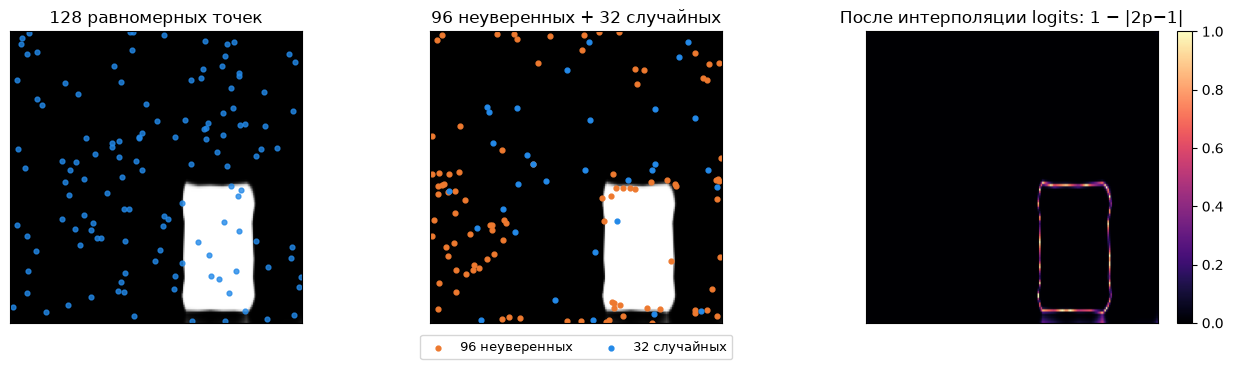

In [69]:
def show_sampling_locations():
    logits = mask.detach().cpu()
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(1234)
        uniform = torch.rand(128, 2)
        focused = uncertain_points(logits, 128)[0]
    y = (torch.arange(128) + .5) / 128
    x = (torch.arange(192) + .5) / 192
    yy, xx = torch.meshgrid(y, x, indexing="ij")
    coordinates = torch.stack([xx, yy], dim=-1).reshape(1, -1, 2)
    probabilities = sample_points(logits, coordinates)[0].reshape(128, 192).sigmoid()
    uncertainty = 1 - (2 * probabilities - 1).abs()
    figure, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    for axis in axes[:2]:
        axis.imshow(probabilities, cmap="gray", vmin=0, vmax=1, extent=(0, 1, 1, 0))
    axes[0].scatter(uniform[:, 0], uniform[:, 1], s=12, color="#2389e8", alpha=.8)
    axes[0].set_title("128 равномерных точек")
    axes[1].scatter(focused[:96, 0], focused[:96, 1], s=12, color="#ed792f", label="96 неуверенных")
    axes[1].scatter(focused[96:, 0], focused[96:, 1], s=12, color="#2389e8", label="32 случайных")
    axes[1].set_title("96 неуверенных + 32 случайных")
    axes[1].legend(loc="upper center", bbox_to_anchor=(.5, -.02), ncol=2, fontsize=9)
    artist = axes[2].imshow(uncertainty, cmap="magma", vmin=0, vmax=1, extent=(0, 1, 1, 0))
    axes[2].set_title("После интерполяции logits: 1 − |2p−1|")
    figure.colorbar(artist, ax=axes[2], fraction=.045)
    for axis in axes:
        axis.set(xlim=(0, 1), ylim=(1, 0), xticks=[], yticks=[])
    figure.tight_layout()
    finish_visual(figure, "06c_sampling_locations")


show_sampling_locations()

### Мини-абляция: равномерные и неуверенные точки

На одной matched-маске фиксируем плотную карту BCE. Выбираем из её пикселей 32/128/512 точек и повторяем выбор 40 раз. Для uniform среднее оценивает плотную BCE; смесь 75% неуверенных и 25% случайных точек меняет эту величину.

Здесь индексируем готовую карту, чтобы изолировать выбор точек от интерполяции. В training-коде выше используется `grid_sample`. На графике — среднее и std по 40 выборкам. Этот опыт сравнивает оценки loss; качество обучения проверяем отдельным запуском ниже.

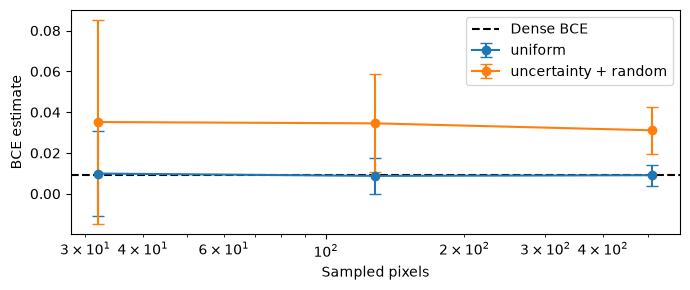

In [70]:
with torch.no_grad():
    pair_target = int(matched[0][1][0])
    full_logits = F.interpolate(trained_output["pred_masks"][0:1, query:query + 1],
                                size=images.shape[-2:], mode="bilinear", align_corners=False).flatten()
    full_truth = targets[0]["masks"][pair_target].flatten()
    pixel_bce = F.binary_cross_entropy_with_logits(full_logits, full_truth, reduction="none").cpu()
    uncertainty = -full_logits.abs().cpu()
counts = (32, 128, 512)
sampling_losses = {name: [] for name in ("uniform", "uncertainty + random")}
generator = torch.Generator().manual_seed(17)
for count in counts:
    samples = {name: [] for name in sampling_losses}
    for repeat in range(40):
        uniform_ids = torch.randint(len(pixel_bce), (count,), generator=generator)
        candidate_ids = torch.randint(len(pixel_bce), (3 * count,), generator=generator)
        important_count = int(0.75 * count)
        important_ids = candidate_ids[uncertainty[candidate_ids].topk(important_count).indices]
        random_ids = torch.randint(len(pixel_bce), (count - important_count,), generator=generator)
        focused_ids = torch.cat([important_ids, random_ids])
        samples["uniform"].append(pixel_bce[uniform_ids].mean().item())
        samples["uncertainty + random"].append(pixel_bce[focused_ids].mean().item())
    for name, values in samples.items():
        sampling_losses[name].append(values)
figure, ax = plt.subplots(figsize=(7, 3))
for name, values in sampling_losses.items():
    values = np.array(values)
    ax.errorbar(counts, values.mean(1), yerr=values.std(1), marker="o", capsize=4, label=name)
ax.axhline(pixel_bce.mean().item(), color="black", linestyle="--", label="Dense BCE")
ax.set(xlabel="Sampled pixels", ylabel="BCE estimate", xscale="log")
ax.legend()
figure.tight_layout()
figure.savefig(ARTIFACTS / "sampling_bias.png", dpi=130)
plt.show()

Измеряем forward+backward после прогрева. `cuda_peak_mib` доступен на CUDA. На маленьких входах затраты на sampling могут превышать экономию от сокращения числа точек.

In [71]:
def benchmark_step(model, images, targets, criterion, repeats=3):
    device = images.device
    model.train()
    times, peaks = [], []
    for index in range(repeats + 1):
        model.zero_grad(set_to_none=True)
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
        synchronize(device)
        started = time.perf_counter()
        criterion(model(images), targets)["loss"].backward()
        synchronize(device)
        if index:
            times.append(time.perf_counter() - started)
            if device.type == "cuda":
                peaks.append(torch.cuda.max_memory_allocated(device) / 2**20)
    model.zero_grad(set_to_none=True)
    return {"forward_backward_ms": 1000 * float(np.median(times)), "cuda_peak_mib": max(peaks) if peaks else None}

In [72]:
for point_count in (0, 128):
    measure = benchmark_step(model, images, targets, SetCriterion(num_classes=2, num_points=point_count).to(DEVICE))
    print("points=", point_count, measure)

points= 0 {'forward_backward_ms': 18.219874997157604, 'cuda_peak_mib': None}
points= 128 {'forward_backward_ms': 14.258832990890369, 'cuda_peak_mib': None}


### Парное обучение: dense ↔ sampled

`multiscale ↔ sampled`: архитектура и стартовые веса совпадают. Меняются и matching по случайным точкам, и mask loss по смеси неуверенных и случайных точек. Их отдельные эффекты этот запуск не разделяет. Сравниваем качество за одинаковое число шагов; время forward+backward измерено выше.

sampled        seed=42: mIoU=0.570, precision=0.500, recall=0.547


sampled        seed=43: mIoU=0.567, precision=0.356, recall=0.491


sampled        seed=44: mIoU=0.681, precision=0.403, recall=0.585


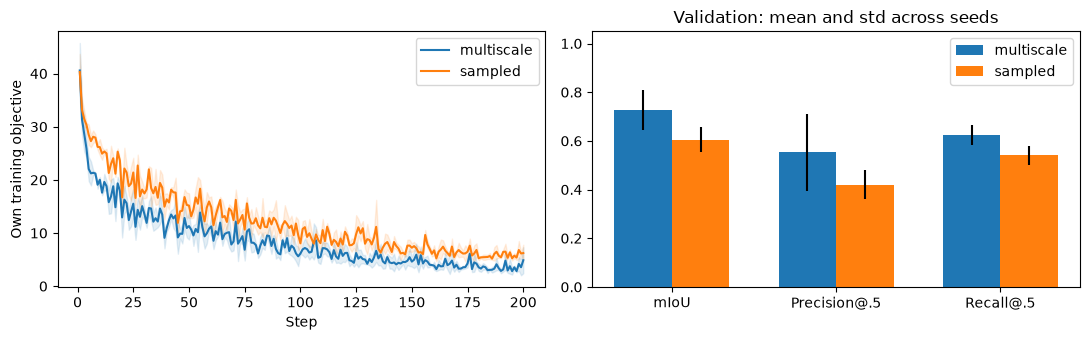

In [73]:
compare_variants("multiscale", "sampled")

## 7. Сравнение вариантов

| Вариант | Маски и классы | Attention | Масштабы memory | Aux loss | Mask loss |
|---|---|---|---|---|---|
| conv | Фиксированные фильтры + mask pooling | — | — | нет | плотный |
| global_pool | Динамические фильтры + mask pooling | global | один | нет | плотный |
| global_no_aux | Queries + mask embeddings | global | один | нет | плотный |
| global | Queries + mask embeddings | global | один | есть | плотный |
| masked | Queries + mask embeddings | masked | один | есть | плотный |
| multiscale | Queries + mask embeddings | masked | три | есть | плотный |
| no_aux | Queries + mask embeddings | masked | три | нет | плотный |
| sampled | Queries + mask embeddings | masked | три | есть | по точкам |

`conv ↔ global_pool` сохраняет классификацию через mask pooling и меняет способ построения масок.

`conv ↔ global_no_aux` сравнивает две архитектуры предсказания набора масок: меняются mask head, classification head и наличие decoder. Число параметров различается.

Остальные пары: `global_no_aux ↔ global` — auxiliary loss; `global ↔ masked` — ограничение attention; `masked ↔ multiscale` — масштабы; `multiscale ↔ no_aux` — auxiliary loss; `multiscale ↔ sampled` — matching и loss по точкам.

Начальные веса pixel decoder, data split, число кандидатов, шагов, optimizer и batch size совпадают. Seeds меняют инициализацию и shuffle. Training objectives имеют разный масштаб; качество сравниваем по validation-метрикам.

### Архитектура, которую мы собрали

Упрощённая модель с query decoder в духе Mask2Former: наш pixel decoder — U-Net. Здесь нет deformable-attention pixel decoder из полной архитектуры. Повторяем нижнюю цепочку для нескольких слоёв; уровень memory выбирается циклически.

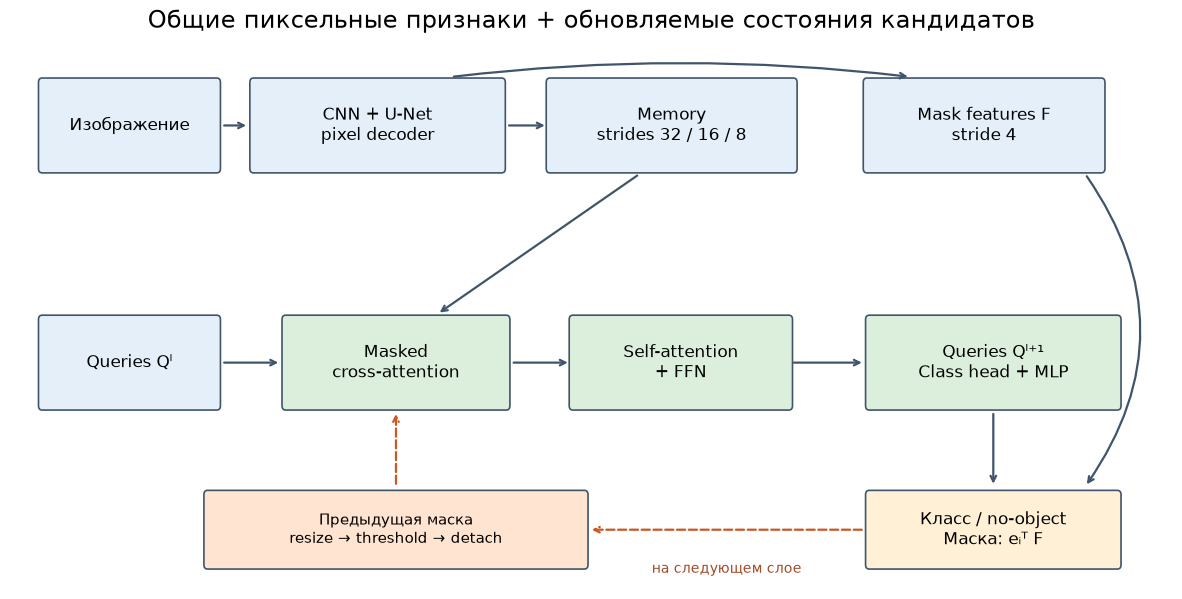

In [74]:
def show_final_architecture():
    figure, axis = diagram_canvas("Общие пиксельные признаки + обновляемые состояния кандидатов", (15, 7))
    diagram_box(axis, (1.1, 4.3), "Изображение", width=1.9)
    diagram_box(axis, (3.8, 4.3), "CNN + U-Net\npixel decoder", width=2.7)
    diagram_box(axis, (7.0, 4.3), "Memory\nstrides 32 / 16 / 8", width=2.65)
    diagram_box(axis, (10.4, 4.3), "Mask features F\nstride 4", width=2.55)
    diagram_arrow(axis, (2.1, 4.3), (2.4, 4.3))
    diagram_arrow(axis, (5.2, 4.3), (5.65, 4.3))
    diagram_arrow(axis, (4.6, 4.75), (9.6, 4.75), curve=-.06)
    diagram_box(axis, (1.1, 2.1), "Queries Qˡ", width=1.9)
    diagram_box(axis, (4.0, 2.1), "Masked\ncross-attention", width=2.4, color="#dcefdc")
    diagram_box(axis, (7.1, 2.1), "Self-attention\n+ FFN", width=2.35, color="#dcefdc")
    diagram_box(axis, (10.5, 2.1), "Queries Qˡ⁺¹\nClass head + MLP", width=2.7, color="#dcefdc")
    for start, end in [(2.1, 2.75), (5.25, 5.9), (8.3, 9.1)]:
        diagram_arrow(axis, (start, 2.1), (end, 2.1))
    diagram_arrow(axis, (6.65, 3.85), (4.45, 2.55))
    diagram_box(axis, (4.0, .55), "Предыдущая маска\nresize → threshold → detach", width=4.1, height=.65, color="#ffe5d1", fontsize=11)
    diagram_arrow(axis, (4.0, .95), (4.0, 1.65), color="#c95823", style="--")
    diagram_box(axis, (10.5, .55), "Класс / no-object\nМаска: eᵢᵀ F", width=2.7, height=.65, color="#fff0d6")
    diagram_arrow(axis, (10.5, 1.65), (10.5, .95))
    diagram_arrow(axis, (11.5, 3.85), (11.5, .95), curve=-.35)
    diagram_arrow(axis, (9.1, .55), (6.1, .55), color="#c95823", style="--")
    axis.text(7.6, .15, "на следующем слое", ha="center", fontsize=10, color="#a14b27")
    finish_visual(figure, "07a_final_architecture")


show_final_architecture()

Сравниваем `conv ↔ global_no_aux` и `multiscale ↔ no_aux`, затем собираем результаты всех вариантов в одну таблицу.

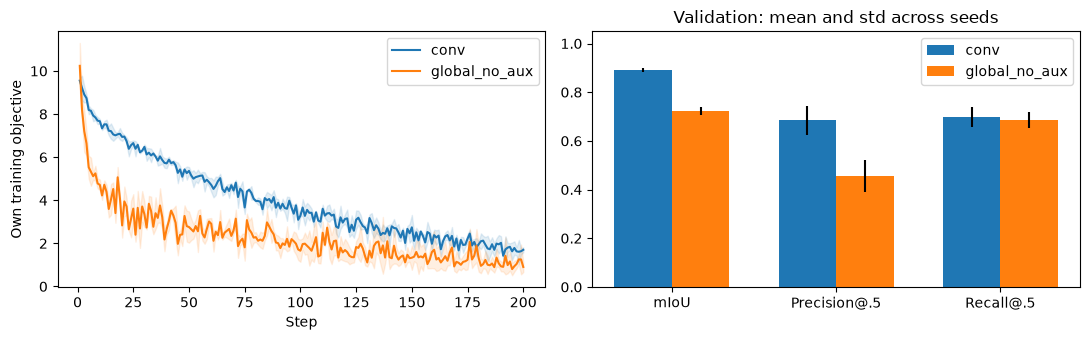

no_aux         seed=42: mIoU=0.784, precision=0.600, recall=0.623


no_aux         seed=43: mIoU=0.787, precision=0.559, recall=0.717


no_aux         seed=44: mIoU=0.714, precision=0.467, recall=0.660


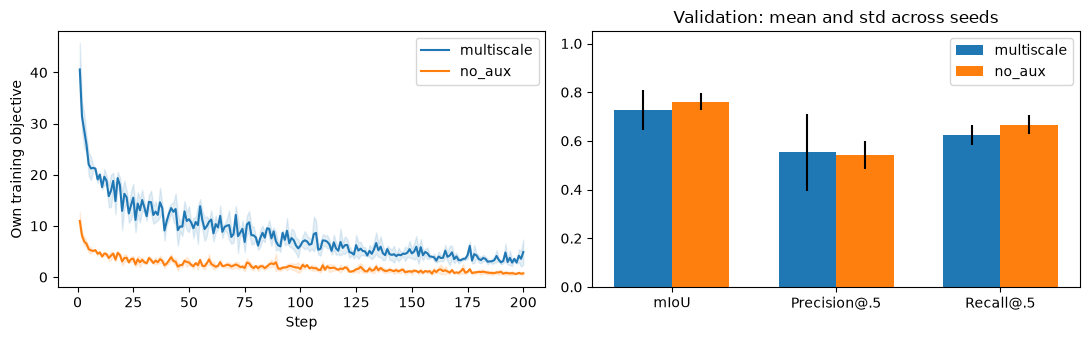

In [75]:
compare_variants("conv", "global_no_aux")
compare_variants("multiscale", "no_aux")

In [76]:
rows, histories = [], {name: [] for name in VARIANTS}
for variant in VARIANTS:
    for seed in SEEDS:
        run = run_ablation(variant, seed)
        rows.append({key: value for key, value in run.items() if key != "history"})
        histories[variant].append([entry["loss"] for entry in run["history"]])
(ARTIFACTS / "comparison.json").write_text(json.dumps(rows, indent=2))
(ARTIFACTS / "ablation_runs.json").write_text(json.dumps(list(ablation_runs.values()), indent=2));

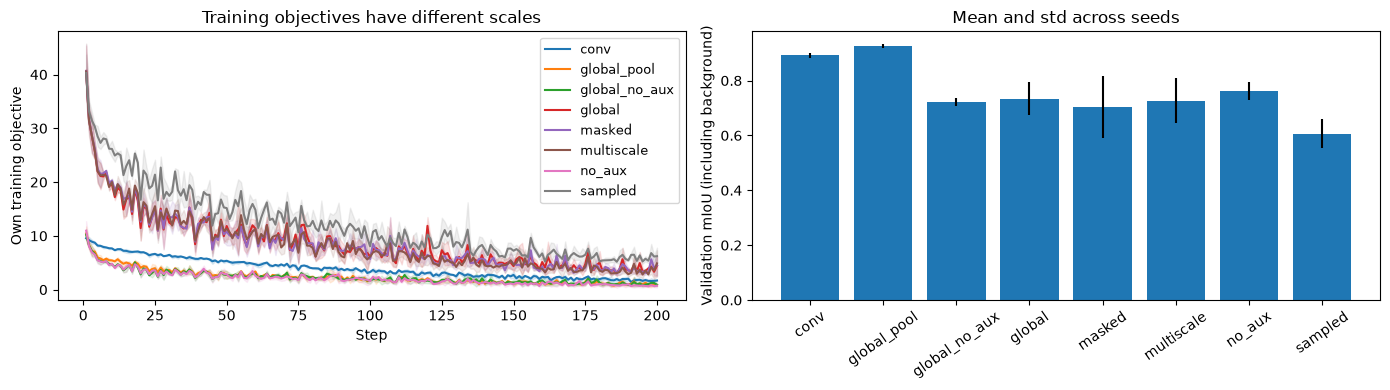

conv          : mIoU=0.892 ± 0.010, parameters=241,139
global_pool   : mIoU=0.925 ± 0.008, parameters=294,643
global_no_aux : mIoU=0.723 ± 0.015, parameters=294,579
global        : mIoU=0.734 ± 0.060, parameters=294,579
masked        : mIoU=0.704 ± 0.113, parameters=294,579
multiscale    : mIoU=0.727 ± 0.081, parameters=294,579
no_aux        : mIoU=0.761 ± 0.034, parameters=294,579
sampled       : mIoU=0.606 ± 0.053, parameters=294,579


In [77]:
figure, axes = plt.subplots(1, 2, figsize=(14, 4))
for variant, curves in histories.items():
    values = np.array(curves)
    steps = np.arange(1, values.shape[1] + 1)
    mean, std = values.mean(0), values.std(0)
    line, = axes[0].plot(steps, mean, label=variant)
    axes[0].fill_between(steps, mean - std, mean + std, color=line.get_color(), alpha=0.12)
axes[0].set(xlabel="Step", ylabel="Own training objective", title="Training objectives have different scales")
axes[0].legend(fontsize=9)

names = list(VARIANTS)
scores = [[row["semantic_miou"] for row in rows if row["variant"] == name] for name in names]
axes[1].bar(names, [np.mean(s) for s in scores], yerr=[np.std(s) for s in scores])
axes[1].set(ylabel="Validation mIoU (including background)", title="Mean and std across seeds")
axes[1].tick_params(axis="x", rotation=35)
figure.tight_layout()
figure.savefig(ARTIFACTS / "comparison.png", dpi=150)
plt.show()

for name, values in zip(names, scores):
    parameters = next(row["parameters"] for row in rows if row["variant"] == name)
    print(f"{name:14s}: mIoU={np.mean(values):.3f} ± {np.std(values):.3f}, parameters={parameters:,}")

### Три метрики для каждого варианта

Среднее и стандартное отклонение по трём seeds на одном validation. Высокий semantic mIoU может сочетаться с ложными instance-предсказаниями или пропущенными объектами.

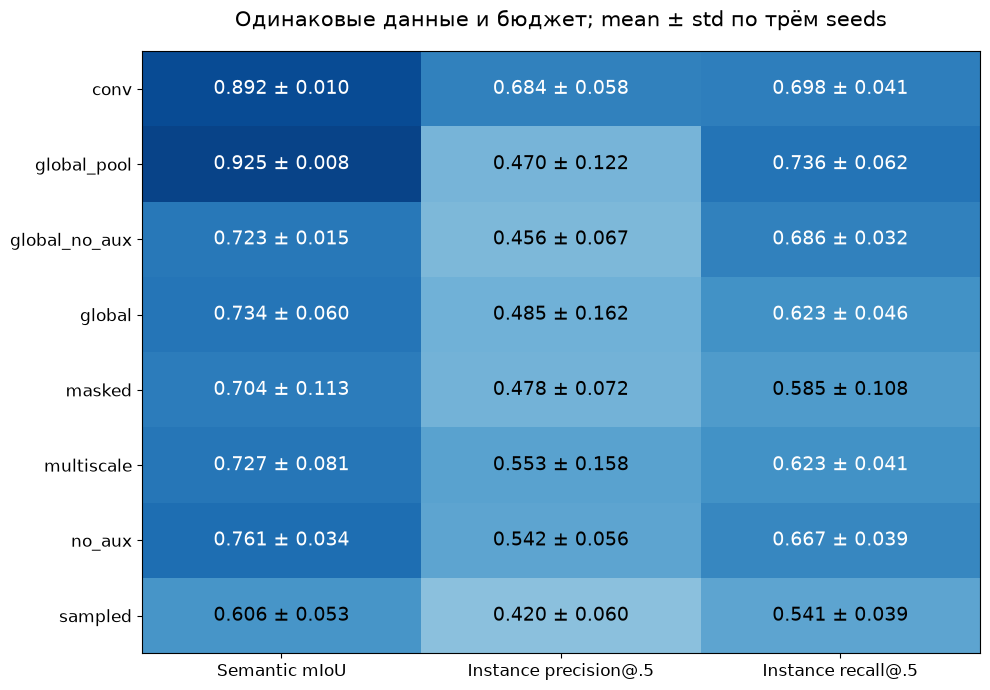

In [78]:
def show_all_metrics():
    variants = list(VARIANTS)
    keys = ["semantic_miou", "instance_precision_50", "instance_recall_50"]
    values = np.array([[[row[key] for key in keys] for row in rows if row["variant"] == name] for name in variants])
    means, stds = values.mean(1), values.std(1)
    figure, axis = plt.subplots(figsize=(10, 7))
    axis.imshow(means, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(len(variants)):
        for j in range(3):
            axis.text(j, i, f"{means[i, j]:.3f} ± {stds[i, j]:.3f}", ha="center", va="center", fontsize=14,
                      color="white" if means[i, j] > .62 else "black")
    axis.set(xticks=range(3), xticklabels=["Semantic mIoU", "Instance precision@.5", "Instance recall@.5"],
             yticks=range(len(variants)), yticklabels=variants)
    axis.tick_params(axis="both", labelsize=12)
    axis.set_title("Одинаковые данные и бюджет; mean ± std по трём seeds", fontsize=15, pad=18)
    figure.tight_layout()
    finish_visual(figure, "07b_all_metrics")


show_all_metrics()

### Результаты на фигурах

В сохранённом прогоне: 8 кандидатов, 200 шагов, seeds 42/43/44. mIoU — среднее ± std; precision/recall — средние по seeds при фиксированном пороге.

| Вариант | Semantic mIoU | Instance precision@0.5 | Instance recall@0.5 |
|---|---|---|---|
| conv | 0.892 ± 0.010 | 0.684 | 0.698 |
| global_pool | 0.925 ± 0.008 | 0.470 | 0.736 |
| global_no_aux | 0.723 ± 0.015 | 0.456 | 0.686 |

При одинаковой классификации через mask pooling динамические фильтры повышают mIoU и recall, но снижают precision: получаем больше ложных instance-предсказаний. Поэтому одного semantic mIoU недостаточно для оценки разделения объектов.

При сравнении conv / global_no_aux свёрточный baseline лучше по mIoU. Замена способа классификации существенно меняет результат. Цвет фигур связан с классом, и mask pooling позволяет классифицировать по цвету.

На парах кругов у global_pool также высокий semantic mIoU при низком instance precision/recall. Эти короткие опыты не показывают общего превосходства query decoder.

Эксперимент с переобучением на восьми изображениях из раздела 5 использует другую выборку.

### Дополнительное чтение

[Пояснения и статьи](../ADDITIONAL_NOTES.md): фиксированные и динамические фильтры, matching, mask pooling, masked attention, промежуточные losses и метрики. Для каждой статьи указаны разделы, связанные с реализацией.

Ниже — численные проверки позиционного кодирования и симметрии queries, затем необязательный пример адаптации к COCO.

## Проверки query decoder

На обученной модели проверяем зависимость embeddings от изображения, прохождение градиента, координаты и симметрию одинаковых queries.

In [79]:
global_model = query_demo
with torch.no_grad():
    global_output = global_model(images)
embeddings = global_output["mask_embeddings"]
embedding_delta = (embeddings[0] - embeddings[1]).abs().mean()
assert embedding_delta > 1e-6
print("Image-conditioned embeddings:", tuple(embeddings.shape))
print("Embedding difference between images:", float(embedding_delta))

loss_original = criterion(global_output, targets)["loss"]
loss_permuted = criterion(global_output, permuted)["loss"]
torch.testing.assert_close(loss_original, loss_permuted)
global_model.zero_grad(set_to_none=True)
criterion(global_model(images), targets)["loss"].backward()
assert global_model.query_features.weight.grad.norm() > 0
print("Query gradient norm:", float(global_model.query_features.weight.grad.norm()))

Image-conditioned embeddings: (4, 8, 32)
Embedding difference between images: 0.05312257632613182
Query gradient norm: 0.5076416730880737


### Мини-абляция: перестановка memory и координаты

Берём один и тот же decoder layer, queries и набор memory-токенов. Без координат перестановка memory не меняет выход. Если оставить координаты на месте и переставить признаки между ними, выход может измениться. Совместная перестановка пар «признак, координата» снова должна сохранить результат.

Проверяется вход attention-блока. CNN уже мог закодировать положение внутри признаков; этот опыт не доказывает обязательность positional encoding для всей модели.

In [80]:
layer = global_model.decoder[0]
with torch.no_grad():
    spatial = global_model.pixels(images[:1])["memories"][0]
    memory = spatial.flatten(2).transpose(1, 2)
    positions = position_encoding(spatial)
    zero_positions = torch.zeros_like(positions)
    queries = global_model.query_features.weight[None]
    query_positions = global_model.query_position.weight[None]
    order = torch.arange(memory.shape[1] - 1, -1, -1, device=DEVICE)
    no_position = layer(queries, query_positions, memory, zero_positions)[0]
    no_position_shuffled = layer(queries, query_positions, memory[:, order], zero_positions)[0]
    with_position = layer(queries, query_positions, memory, positions)[0]
    shuffled_features = layer(queries, query_positions, memory[:, order], positions)[0]
    shuffled_pairs = layer(queries, query_positions, memory[:, order], positions[:, order])[0]
torch.testing.assert_close(no_position, no_position_shuffled)
torch.testing.assert_close(with_position, shuffled_pairs)
for name, before, after in [("No positions", no_position, no_position_shuffled),
                            ("Fixed coordinates, shuffled features", with_position, shuffled_features),
                            ("Shuffled feature-coordinate pairs", with_position, shuffled_pairs)]:
    print(f"{name}: mean change={(before - after).abs().mean().item():.8f}")

No positions: mean change=0.00000008
Fixed coordinates, shuffled features: mean change=0.04211446
Shuffled feature-coordinate pairs: mean change=0.00000009


### Дополнительная проверка: одинаковые queries

При одинаковых query features и query positions все слоты проходят один и тот же forward и дают одинаковые маски. Проверим отдельно features, positions и оба набора параметров. Это симметрия текущего forward: разные цели, назначенные matching, могут нарушить её при обучении.

In [81]:
query_features = global_model.query_features.weight.detach().clone()
query_positions = global_model.query_position.weight.detach().clone()
try:
    with torch.no_grad():
        for same_features, same_positions in ((False, False), (True, False), (False, True), (True, True)):
            global_model.query_features.weight.copy_(query_features[:1].expand_as(query_features) if same_features else query_features)
            global_model.query_position.weight.copy_(query_positions[:1].expand_as(query_positions) if same_positions else query_positions)
            output = global_model(images[:1])
            spread = (output["pred_masks"] - output["pred_masks"][:, :1]).abs().max()
            print(f"same features={same_features}, same positions={same_positions}: max mask difference={spread.item():.6f}")
            if same_features and same_positions:
                torch.testing.assert_close(output["pred_masks"], output["pred_masks"][:, :1].expand_as(output["pred_masks"]))
finally:
    with torch.no_grad():
        global_model.query_features.weight.copy_(query_features)
        global_model.query_position.weight.copy_(query_positions)

same features=False, same positions=False: max mask difference=45.927765
same features=True, same positions=False: max mask difference=2.694658
same features=False, same positions=True: max mask difference=45.293915
same features=True, same positions=True: max mask difference=0.000000


## Дополнение: COCO и ResNet

Для естественных изображений заменяем encoder на ResNet, сохраняя pixel decoder, queries и criterion.
Дополнительные зависимости:

```python
%pip install torchvision pillow pycocotools
```

`COCO_ROOT` — папка с `val2017/` и `annotations/instances_val2017.json` из [COCO 2017](https://cocodataset.org/#download).
Loader исключает изображения с crowd-разметкой выбранных классов до разделения на train/val. ImageNet-веса скачиваются при первом запуске.
`RUN_COCO = True` включает обучение; для него рекомендуется CUDA.

In [82]:
class ResNetEncoder(nn.Module):
    def __init__(self, name="resnet18", pretrained=False):
        super().__init__()
        from torchvision import models

        choices = {
            "resnet18": (models.resnet18, models.ResNet18_Weights.DEFAULT, (64, 128, 256, 512)),
            "resnet50": (models.resnet50, models.ResNet50_Weights.DEFAULT, (256, 512, 1024, 2048)),
        }
        if name not in choices:
            raise ValueError(f"Unknown backbone: {name}")
        constructor, weights, self.channels = choices[name]
        net = constructor(weights=weights if pretrained else None)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.stages = nn.ModuleList([net.layer1, net.layer2, net.layer3, net.layer4])

    def forward(self, images):
        x = self.stem(images)
        features = []
        for stage in self.stages:
            x = stage(x)
            features.append(x)
        return features

In [83]:
class CocoInstancesDataset(Dataset):
    def __init__(self, root, split="train", train_size=500, val_size=100,
                 image_size=(256, 384), seed=42, class_names=("person",)):
        from pycocotools.coco import COCO

        if split not in ("train", "val"):
            raise ValueError("split must be train or val")
        self.root, self.image_size = Path(root), tuple(image_size)
        self.class_names = tuple(class_names)
        self.coco = COCO(str(self.root / "annotations/instances_val2017.json"))
        categories = self.coco.loadCats(self.coco.getCatIds(catNms=list(class_names)))
        by_name = {c["name"]: c["id"] for c in categories}
        self.category_to_label = {by_name[name]: index for index, name in enumerate(class_names)}
        image_ids = set()
        crowd_ids = set()
        for category in self.category_to_label:
            image_ids.update(self.coco.getImgIds(catIds=[category]))
            crowd_annotations = self.coco.loadAnns(self.coco.getAnnIds(catIds=[category], iscrowd=True))
            crowd_ids.update(annotation["image_id"] for annotation in crowd_annotations)
        image_ids = np.array(sorted(image_ids - crowd_ids))
        np.random.default_rng(seed).shuffle(image_ids)
        if len(image_ids) < train_size + val_size:
            raise ValueError(f"Need {train_size + val_size} images, found {len(image_ids)}")
        self.image_ids = image_ids[:train_size] if split == "train" else image_ids[train_size:train_size + val_size]

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        from PIL import Image

        image_id = int(self.image_ids[index])
        info = self.coco.loadImgs([image_id])[0]
        height, width = self.image_size
        image = Image.open(self.root / "val2017" / info["file_name"]).convert("RGB")
        image = np.asarray(image.resize((width, height), Image.Resampling.BILINEAR)).copy()
        image = torch.from_numpy(image).permute(2, 0, 1).float() / 255
        image = (image - torch.tensor([0.485, 0.456, 0.406])[:, None, None]) / torch.tensor([0.229, 0.224, 0.225])[:, None, None]
        masks, labels = [], []
        annotations = self.coco.loadAnns(self.coco.getAnnIds(imgIds=[image_id]))
        for ann in annotations:
            if ann["category_id"] not in self.category_to_label or ann.get("iscrowd", 0):
                continue
            mask = Image.fromarray(self.coco.annToMask(ann))
            mask = torch.from_numpy(np.asarray(mask.resize((width, height), Image.Resampling.NEAREST)).copy())
            if mask.any():
                masks.append(mask.float())
                labels.append(self.category_to_label[ann["category_id"]])
        return image, {
            "labels": torch.tensor(labels, dtype=torch.long),
            "masks": torch.stack(masks) if masks else torch.zeros(0, height, width),
        }

In [84]:
RUN_COCO = False
COCO_ROOT = Path("data/coco")
COCO_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
COCO_STEPS = 3000

if RUN_COCO:
    seed_everything(42)
    data_config = dict(root=COCO_ROOT, train_size=500, val_size=100,
                       image_size=(256, 384), seed=123, class_names=("person",))
    coco_train = CocoInstancesDataset(split="train", **data_config)
    coco_val = CocoInstancesDataset(split="val", **data_config)
    coco_loader = DataLoader(coco_train, batch_size=4, shuffle=True, collate_fn=collate_instances,
                             generator=torch.Generator().manual_seed(42))
    coco_val_loader = DataLoader(coco_val, batch_size=4, collate_fn=collate_instances)
    coco_model = QuerySegmenter(num_classes=1, dim=128, num_queries=100, heads=8, layers=6,
                                masked_attention=True, multiscale=True,
                                backbone="resnet18", pretrained=True).to(COCO_DEVICE)
    coco_criterion = SetCriterion(num_classes=1, num_points=2048).to(COCO_DEVICE)
    coco_history = train_steps(coco_model, coco_loader, coco_criterion, steps=COCO_STEPS,
                               learning_rate=0.0001, device=COCO_DEVICE, log_every=100)
    print(evaluate(coco_model, coco_val_loader, 1, COCO_DEVICE))
    torch.save(coco_model.state_dict(), ARTIFACTS / "coco_model.pt")